# Sesión 1 · Del simulador al óptimo exacto: el problema de Fritz Wasser

**Curso:** Optimización metaheurística orientada a modelación hidrogeológica
**UNAM · Instituto de Geología · Educación Continua y a Distancia · noviembre de 2026**
Dr. Abelardo Rodríguez Pretelín · Laboratorio HIDRA

---

### Cómo usar este cuaderno

- Cada caja gris es una **celda**. Se ejecuta con el triángulo de la izquierda o con `Shift + Enter`. Ejecútalas **en orden**, de arriba hacia abajo.
- El texto que empieza con `#` dentro del código es un comentario: Python lo ignora, está para ti.
- Arriba a la derecha debe decir **.venv** como kernel. Si no, revisa la sección 8 de la guía de instalación.
- Las celdas marcadas con ✏️ **Inténtalo** son para que cambies algo y vuelvas a ejecutar. Equivocarse está permitido: solo vuelve a correr la celda.

### Qué vas a lograr hoy

1. Usar Python y NumPy lo suficiente para plantear un problema de optimización.
2. Correr un **simulador real de aguas subterráneas** (el del laboratorio) con una sola línea.
3. Resolver el problema de Fritz Wasser **con garantía de óptimo global** y leer la solución en un mapa.
4. Reconocer lo que puede salir mal (no acotado, infactible, degenerado) y leerlo en términos hidrogeológicos.
5. Entender cuándo basta el método clásico y cómo una metaheurística resuelve lo que `linprog` ya no puede.

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 0 · PREPARACIÓN</p>

## 0 · Preparación (5 min)

La primera línea le dice a Python dónde vive el módulo del curso, `hidra.py`, que está una carpeta arriba.
La segunda carga ese módulo. La tercera comprueba que todo funciona. Debe terminar con **ENTORNO LISTO**.

In [1]:
import sys, os; sys.path.append('..')    # la carpeta de arriba contiene hidra.py
import hidra                              # el acuífero del curso
os.makedirs("Información/figuras", exist_ok=True)   # aquí se guardan las figuras del cuaderno
hidra.verificar_entorno()

Python 3.11.14 | numpy 2.4.1 | scipy 1.17.0 | matplotlib 3.10.8 | plotly 6.7.0 | otter 7.0.0
Simulador listo: una corrida tarda 0.04 s. Resultado(bombeos=[100.0, 100.0, 100.0] m³/d → abatimientos en pozos=[0.90, 0.92, 0.92] m, humedal=0.48 m)
ENTORNO LISTO


<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 1 · PYTHON EN 15 MINUTOS</p>

## 1 · Python en 15 minutos: lo de hoy, y la caja de herramientas para las sesiones 2 a 4

No vamos a aprender Python completo (para eso está el tutorial de la tarea). En clase vamos a aprender **seis cosas**,
en el orden en que las necesitaremos. Cada una viene con un ejemplo y un *Inténtalo*.

### 1.1 Variables y números

Una variable es un nombre que guarda un valor. `print` muestra cosas en pantalla. Las `f"..."` permiten meter variables dentro de un texto.

In [2]:
bombeo = 300            # metros cúbicos por día
abatimiento = 2.5       # metros
print(bombeo * 2)
print(f"El pozo bombea {bombeo} m³/d y abate {abatimiento} m")

600
El pozo bombea 300 m³/d y abate 2.5 m


✏️ **Inténtalo:** cambia `bombeo` a 450 y vuelve a ejecutar la celda. ¿Qué cambió en las dos líneas de salida?

### 1.2 Listas

Una lista guarda varios valores en orden. **Python cuenta desde cero**: el primer elemento es el `[0]`.

In [3]:
bombeos = [300, 300, 300]     # pozo 1, pozo 2, pozo 3
print(bombeos[0])              # el primero
print(bombeos[2])              # el tercero (¡no el segundo!)
bombeos[1] = 450               # cambiamos el del pozo 2
print(bombeos)
print(len(bombeos), "pozos")

300
300
[300, 450, 300]
3 pozos


✏️ **Inténtalo:** ¿qué pasa si pides `bombeos[3]`? Pruébalo en una celda nueva (botón **+ Code** arriba). Leer el error es parte del oficio: dice `index out of range`, «índice fuera de rango».

### 1.3 NumPy: arreglos y la operación que lo cambia todo

NumPy es la librería de matemáticas de Python. Sus **arreglos** se parecen a las listas, pero saben hacer aritmética
de golpe sobre todos sus elementos, y saben multiplicar matrices. Por convención se importa como `np`.

![Python y NumPy: el lenguaje del curso y su librería de matemáticas](Información/figuras/lamina_python_numpy.png)

In [4]:
import numpy as np

p = np.array([300, 300, 300])       # un arreglo (vector) de 3 bombeos
print(p * 2)                          # multiplica los tres a la vez
print(p.sum(), p.max(), p.argmax())   # suma, máximo y posición del máximo

[600 600 600]
900 300 0


Hoy vamos a descubrir que el abatimiento en los pozos se obtiene **multiplicando una matriz por el vector de bombeos**.
En NumPy esa multiplicación se escribe con `@`. Mira:

![La operación que lo cambia todo: matriz por vector con @](Información/figuras/lamina_matriz_por_vector.png)

In [5]:
alpha = np.array([[0.0068, 0.0010, 0.0011],
                  [0.0010, 0.0071, 0.0011],
                  [0.0011, 0.0011, 0.0070]])    # una matriz 3x3 (de momento, números inventados)

s = alpha @ p                                   # matriz por vector
print(s)                                        # tres abatimientos, uno por pozo
print(alpha[0, 1])                              # fila 0, columna 1
print(alpha[:, 2])                              # toda la columna 2

[2.67 2.76 2.76]
0.001
[0.0011 0.0011 0.007 ]


✏️ **Inténtalo:** calcula a mano el primer valor de `s`: $0.0068 \cdot 300 + 0.0010 \cdot 300 + 0.0011 \cdot 300$. ¿Coincide con lo que imprimió NumPy?

#### Las demás herramientas de NumPy que usaremos hoy

Son pocas y aparecen una y otra vez en el cuaderno y en la Tarea 1. Cada celda es un ejemplo con la misma matriz inventada.

**Crear arreglos.** `np.array` convierte una lista; `np.zeros` fabrica un arreglo de ceros para llenarlo después (así fabricaremos
la matriz de respuesta en la sección 4); `np.linspace` reparte valores entre dos extremos. `.shape` dice cuántas filas y columnas tiene.

In [6]:
vacia = np.zeros((3, 3))             # 3 filas x 3 columnas, todo en cero
print(vacia.shape)                   # (3, 3)
print(np.linspace(0, 600, 5))        # 5 valores igualmente espaciados de 0 a 600

(3, 3)
[  0. 150. 300. 450. 600.]


**Leer, recortar y llenar.** `[fila, columna]` lee un elemento; los dos puntos `:` significan «todas»; `:2` significa «las dos primeras».
Asignar a una rebanada llena una columna completa de un golpe: así, dentro de un `for`, se arma una matriz columna por columna.

In [7]:
print(alpha[0, 1])                   # fila 0, columna 1
print(alpha[:, 2])                   # toda la columna 2 (lo que abate el pozo 3)

M = np.zeros((3, 3))
for j in range(3):
    M[:, j] = alpha[:, j] * 100      # columna j: lo que abate el pozo j con 100 m³/d
print(M[:, :2])                      # solo las columnas 0 y 1 (los pozos 1 y 2)

0.001
[0.0011 0.0011 0.007 ]
[[0.68 0.1 ]
 [0.1  0.71]
 [0.11 0.11]]


**Apilar.** `np.vstack` pone una fila debajo de una matriz; `np.concatenate` y `np.append` alargan un vector. Así entrará el humedal
en la sección 6: como una fila más de la matriz y un límite más del vector.

In [8]:
fila_humedal = np.array([0.0017, 0.0018, 0.0012])   # inventada, como la matriz
A = np.vstack([alpha, fila_humedal])                 # 4 filas: tres pozos y el humedal
limites = np.concatenate([[3.0, 3.0, 3.0], [1.25]])  # lo mismo que np.append([3.0, 3.0, 3.0], 1.25)
print(A.shape, limites)

(4, 3) [3.   3.   3.   1.25]


**Comparar y resumir.** Comparar un arreglo con otro da un arreglo de `True` y `False`, uno por elemento; `.all()` pregunta si todos
son verdaderos y `.any()` si alguno lo es. `np.round` redondea para leer, y `.min()`, `.max()`, `.argmin()`, `.argmax()` resumen.

In [9]:
s = A @ p                            # cuatro abatimientos: tres pozos y el humedal
print(np.round(s, 2))
cumple = s <= limites                # una respuesta por regla
print(cumple, "| ¿todas?", cumple.all(), "| ¿alguna?", cumple.any())
holgura = limites - s                # lo que le sobra a cada regla (negativa = rota)
print(np.round(holgura, 2), "| la más apretada es la", holgura.argmin())

[2.67 2.76 2.76 1.41]
[ True  True  True False] | ¿todas? False | ¿alguna? True
[ 0.33  0.24  0.24 -0.16] | la más apretada es la 3


✏️ **Inténtalo:** baja el bombeo a `p = np.array([300, 300, 150])` y vuelve a ejecutar la última celda. ¿Ya se cumplen todas las reglas?

![Las herramientas de NumPy del día y dónde vuelven a aparecer](Información/figuras/lamina_herramientas_numpy.png)

| Herramienta | Qué hace | Dónde la vuelves a ver |
|---|---|---|
| `np.array`, `@` | vector y matriz por vector | secciones 2 a 6 y Tarea 1 |
| `np.zeros`, `M[:, j] = ...` | fabricar una matriz columna por columna | sección 4 y Tarea 1, etapa 2 |
| `[:, 2]`, `[:, :2]` | separar el pozo 3 de los pozos libres | secciones 5 y 6, Tarea 1 |
| `np.vstack`, `np.concatenate`, `np.append` | agregar el humedal (o un vecino) | sección 6 y Tarea 1, etapas 3 y 4 |
| `<=`, `.all()`, `.any()` | ¿cumple las reglas? | secciones 2.2 y 3, Tarea 1 |
| `np.round`, `np.abs`, `.max()`, `.argmin()` | leer y comparar resultados | sección 4 y en adelante |

### 1.4 Funciones

Una función empaqueta un cálculo para reutilizarlo. Se define con `def`, recibe datos entre paréntesis y devuelve algo con `return`.

In [10]:
def bombeo_total(bombeos):
    return sum(bombeos)

print(bombeo_total([300, 300, 300]))
print(bombeo_total([341, 329, 300]))

900
970


### 1.5 El ciclo `for`

Repite un bloque de código una vez por cada elemento. `range(3)` produce 0, 1, 2. Fíjate en la **sangría**: lo que está
desplazado hacia la derecha es lo que se repite.

In [11]:
for j in range(3):
    print("pozo", j + 1, "bombea", bombeos[j], "m³/d")

pozo 1 bombea 300 m³/d
pozo 2 bombea 450 m³/d
pozo 3 bombea 300 m³/d


### 1.6 Una gráfica

Matplotlib dibuja. `plt.plot(x, y)` traza una línea, `plt.show()` la muestra. Aquí graficamos cómo crece el abatimiento del
pozo 1 cuando solo él bombea, usando la matriz inventada de arriba.

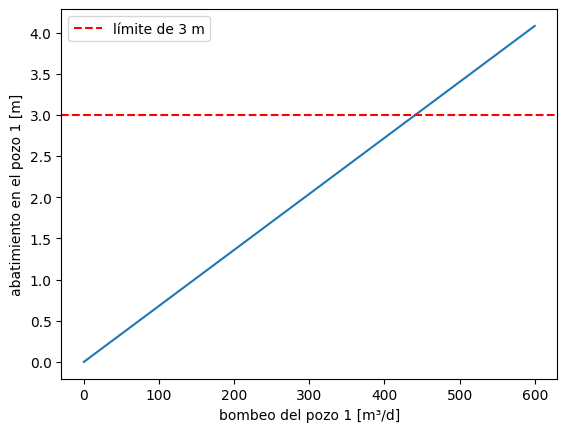

In [12]:
import matplotlib.pyplot as plt

bombeo_p1 = np.linspace(0, 600, 50)              # 50 valores entre 0 y 600
abatimiento_p1 = alpha[0, 0] * bombeo_p1         # una recta

plt.plot(bombeo_p1, abatimiento_p1)
plt.axhline(3.0, color="red", linestyle="--", label="límite de 3 m")
plt.xlabel("bombeo del pozo 1 [m³/d]"); plt.ylabel("abatimiento en el pozo 1 [m]")
plt.legend(); plt.show()

✏️ **Inténtalo:** lee en la gráfica a partir de qué bombeo se cruza el límite de 3 m. Luego compruébalo con una línea de código: `3.0 / alpha[0, 0]`.

Con esto basta **para hoy**: el resto de este cuaderno usa únicamente estas seis cosas. La subsección 1.7 trae lo que necesitarás
en las sesiones 2 a 4. **En clase la saltamos**; hazla en casa antes del martes 10 (unos 25 minutos).

### 1.7 Para las sesiones 2 a 4: la caja de herramientas (en casa, unos 25 minutos)

Los cuadernos del enjambre (sesión 2), de varios objetivos (sesión 3) y de la robustez (sesión 4) usan ocho herramientas más de Python.
Están aquí, con la misma matriz inventada de arriba, para que el martes 10 ninguna línea de código sea nueva.

| | Herramienta | Dónde la vuelves a ver |
|---|---|---|
| a | `if`, `elif`, `else`, `and`, `or` | S2: ¿mejoró la partícula su récord? · S3: ¿la decisión rompe una regla? |
| b | diccionarios `{'clave': valor}` | S2: el problema y cada partícula · S3: los resultados · S4: los parámetros de OMOPSO |
| c | funciones con argumentos por nombre, dos resultados y `lambda` | S2–S4: `pso.PSO(problema, MaxIter=200)`, `CostFunction=lambda x: ...` |
| d | listas por comprensión y `append` | S2: el historial del enjambre · S3: el frente como arreglo |
| e | azar reproducible con semilla | S2: el enjambre arranca al azar · S4: las muestras de la incertidumbre |
| f | resumir muchos resultados: máscaras, `mean`, `percentile`, `argmax` | S3: filtrar soluciones · S4: media, peor caso y riesgo |
| g | gráficas de varios paneles, `scatter` e histogramas | S3: los frentes de Pareto · S4: comparar decisiones |
| h | objetos con punto, medir el tiempo y dar formato a los números | S3 y S4: cuánto tarda OMOPSO; todas las tablas |

#### a) Decidir: `if`, `elif`, `else`

Lo que está desplazado a la derecha solo se ejecuta si la condición es verdadera. `and` y `or` juntan condiciones.

In [13]:
s_pozo = 3.4                                   # abatimiento de un pozo [m]
if s_pozo > 3.0:
    print("INFACTIBLE: el pozo pasa de 3 m")
elif s_pozo > 2.8:
    print("factible, pero casi en el límite")
else:
    print("factible con holgura")

q = np.array([300, 300, 300])
s_q = alpha @ q
if (s_q > 3.0).any() or fila_humedal @ q > 1.25:       # ¿algún pozo pasa de 3 m, o el humedal de 1.25 m?
    print("la decisión", q, "rompe alguna regla")

INFACTIBLE: el pozo pasa de 3 m
la decisión [300 300 300] rompe alguna regla


✏️ **Inténtalo:** cambia `s_pozo` a 2.9 y luego a 2.0. ¿Qué rama se ejecuta en cada caso?

#### b) Diccionarios: datos con nombre

Una lista guarda valores por posición; un **diccionario** los guarda por nombre. Así se describe un problema de optimización en las
sesiones 2 a 4, y así guarda el enjambre cada partícula.

In [14]:
problema = {'CostFunction': None, 'nVar': 2, 'VarMin': 0, 'VarMax': 1000}
print(problema['nVar'], problema['VarMax'])    # se pide por nombre

problema['VarMax'] = 800                       # cambiar un valor
for clave, valor in problema.items():          # recorrer nombre y valor
    print(f"{clave:12s} → {valor}")

otro = dict(problema, nVar=3)                  # una copia con un cambio; el original no se toca
print(otro['nVar'], problema['nVar'])

enjambre = [{'position': np.array([300., 150.]), 'cost': -750.0},      # una lista de diccionarios:
            {'position': np.array([200., 400.]), 'cost': -600.0}]      # una partícula por renglón
print(enjambre[1]['position'], enjambre[1]['cost'])

2 1000
CostFunction → None
nVar         → 2
VarMin       → 0
VarMax       → 800
3 2
[200. 400.] -600.0


✏️ **Inténtalo:** agrega a `problema` la clave `'nPop'` con el valor 30 y muéstrala.

#### c) Funciones: argumentos por nombre, dos resultados y `lambda`

Un argumento puede traer un **valor por defecto** y pasarse **por nombre**. Una función puede devolver **dos cosas**, que se
desempacan con una coma. Y `lambda` escribe una función de una sola línea, útil para **pasarle una función a otra función**: así le
diremos al enjambre qué tiene que optimizar.

In [15]:
def abatimiento(q, matriz=alpha, limite=3.0):
    s = matriz @ q
    return s, (s <= limite).all()              # devuelve dos cosas

s_q, cumple = abatimiento(np.array([300, 300, 300]))          # se desempacan
print(np.round(s_q, 2), cumple)
print(abatimiento(np.array([300, 300, 300]), limite=2.7)[1])  # el mismo cálculo con otro límite, pasado por nombre

total = lambda q: q.sum()                      # una función de una línea

def mejor_de(funcion, candidatos):             # una función que recibe otra función
    valores = [funcion(c) for c in candidatos]
    return candidatos[int(np.argmax(valores))]

print(mejor_de(total, [np.array([300, 150, 300]), np.array([200, 400, 300])]))

[2.67 2.76 2.76] True
False
[200 400 300]


En la sesión 2 verás exactamente esto: `gbest, pop = pso.PSO(problema, MaxIter=200, PopSize=50)` (dos resultados, argumentos por
nombre) y `dict(problema, CostFunction=lambda x: ...)` (un diccionario con una función adentro).

✏️ **Inténtalo:** escribe `promedio = lambda q: q.mean()` y úsala con `mejor_de`. ¿Elige la misma decisión que `total`?

#### d) Listas por comprensión y acumular con `append`

`[expresión for x in lista]` construye una lista nueva en una línea. `append` agrega al final de una lista: así se guarda el
**historial** de un algoritmo, iteración por iteración. `np.inf` es «infinito»: cualquier número lo mejora.

In [16]:
bombeos = [100, 200, 300, 400, 500]
s_p1 = np.array([alpha[0, 0] * b for b in bombeos])          # el abatimiento del pozo 1 con cada bombeo
print(np.round(s_p1, 2))

historial, record = [], -np.inf
for b in [300, 120, 450, 410, 200]:            # cinco propuestas, en orden
    if alpha[0, 0] * b <= 3.0 and b > record:  # factible y mejor que el récord
        record = b
    historial.append(record)
print(historial)                               # el récord después de cada propuesta

[0.68 1.36 2.04 2.72 3.4 ]
[300, 300, 300, 410, 410]


✏️ **Inténtalo:** ¿por qué la propuesta 450 no cambió el récord? Compruébalo con `alpha[0, 0] * 450`.

#### e) Azar reproducible: la semilla

Los métodos de las sesiones 2 a 4 usan números al azar. Con una **semilla** fija, todos obtenemos los mismos números y los
resultados se pueden repetir y comparar.

In [17]:
np.random.seed(0)                              # la semilla
print(np.random.uniform(0, 1000, 3))           # tres bombeos al azar entre 0 y 1000
np.random.seed(0)
print(np.random.uniform(0, 1000, 3))           # los mismos tres

rng = np.random.default_rng(1)                 # la forma moderna: un generador propio
print(np.round(rng.normal(0, 0.5, 5), 3))      # cinco números de una normal con media 0 y desviación 0.5

[548.81350393 715.18936637 602.76337607]
[548.81350393 715.18936637 602.76337607]
[ 0.173  0.411  0.165 -0.652  0.453]


✏️ **Inténtalo:** borra las dos líneas `np.random.seed(0)` y ejecuta la celda dos veces. ¿Qué cambia?

#### f) Resumir muchos resultados: máscaras, `mean`, `percentile`, `argmax`

Con miles de decisiones (o de geologías) no se mira una por una: se **filtra** con una máscara de verdaderos y falsos y se
**resume**. `axis=1` opera a lo largo de cada fila; `axis=0`, a lo largo de cada columna.

In [18]:
rng = np.random.default_rng(2)
Q = rng.uniform(0, 600, size=(1000, 3))        # 1 000 decisiones al azar, una por fila
S = Q @ alpha.T                                # sus abatimientos: 1 000 filas, 3 columnas
factible = (S <= 3.0).all(axis=1)              # la máscara: True en las filas que cumplen todo
Z = Q.sum(axis=1)                              # el bombeo total de cada decisión

print(factible.sum(), "de", len(Q), "son factibles")
print("fracción que rompe alguna regla:", (~factible).mean())
mejor = np.argmax(np.where(factible, Z, -np.inf))          # la mejor entre las factibles
print("la mejor factible:", np.round(Q[mejor]), "con Z =", round(Z[mejor], 1))
print("Z de las factibles: media", round(Z[factible].mean(), 1), "· percentil 10:", round(np.percentile(Z[factible], 10), 1))
print("abatimiento medio por pozo:", np.round(S.mean(axis=0), 2))

228 de 1000 son factibles
fracción que rompe alguna regla: 0.772
la mejor factible: [333. 236. 328.] con Z = 896.3
Z de las factibles: media 539.3 · percentil 10: 330.6
abatimiento medio por pozo: [2.67 2.77 2.79]


La «fracción que rompe alguna regla» es, con otro nombre, el **riesgo** de la sesión 4; el percentil 10 es un «peor caso».

✏️ **Inténtalo:** cambia el límite a 2.5 m. ¿Cuántas decisiones quedan factibles?

#### g) Gráficas de varios paneles

`plt.subplots(1, 2)` crea dos paneles lado a lado; cada uno se dibuja por separado. `scatter` dibuja puntos e `hist` un histograma.

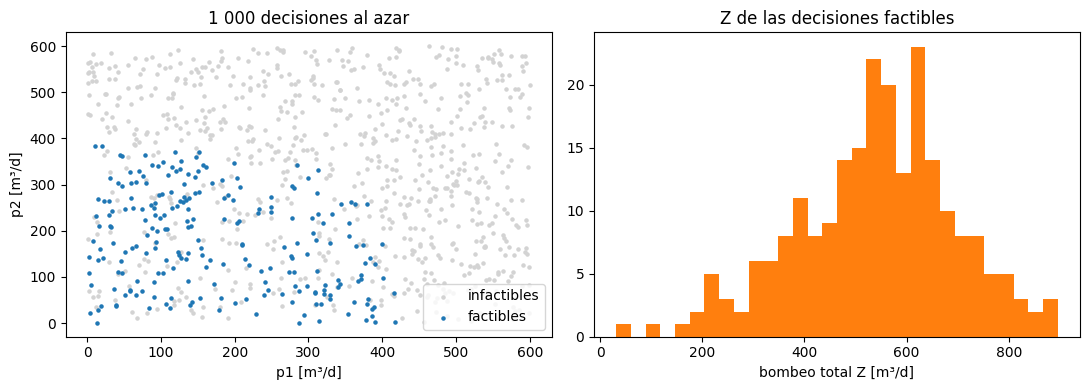

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.scatter(Q[~factible, 0], Q[~factible, 1], s=5, color="lightgray", label="infactibles")
ax1.scatter(Q[factible, 0], Q[factible, 1], s=5, color="tab:blue", label="factibles")
ax1.set_xlabel("p1 [m³/d]"); ax1.set_ylabel("p2 [m³/d]"); ax1.set_title("1 000 decisiones al azar"); ax1.legend()
ax2.hist(Z[factible], bins=30, color="tab:orange")
ax2.set_xlabel("bombeo total Z [m³/d]"); ax2.set_title("Z de las decisiones factibles")
plt.tight_layout(); plt.show()

#### h) Objetos, tiempo y formato

Un arreglo de NumPy (y el `Resultado` de hidra que verás enseguida) es un **objeto**: guarda datos y sabe hacer cosas, y ambas se
piden con un punto. `time.time()` mide cuánto tarda algo. Dentro de una `f"..."`, lo que va después de `:` da formato al número.

In [20]:
import time

t0 = time.time()
S_grande = rng.uniform(0, 600, size=(200_000, 3)) @ alpha.T
print(f"200 000 decisiones evaluadas en {time.time() - t0:.3f} s")

print(Q.shape, Q.ndim)                         # datos del objeto: sin paréntesis
print(np.round(Q.max(axis=0)))                 # cosas que sabe hacer: con paréntesis

print(f"{807.3412:.2f} m³/d | {0.0712:.1%} | {'pozo 1':>8s} |")    # dos decimales, porcentaje, texto alineado

200 000 decisiones evaluadas en 0.005 s
(1000, 3) 2
[600. 600. 600.]
807.34 m³/d | 7.1% |   pozo 1 |


✏️ **Inténtalo:** imprime `0.1234` como porcentaje sin decimales (`:.0%`) y `969.92` con un decimal.

Con la sección 1 completa tienes todo el Python del curso. Lo que aparezca de nuevo en las sesiones 2 a 4 (los métodos `pso.PSO`
y `OMOPSO`) se explicará ahí mismo.

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 2 · EL PROBLEMA Y EL SIMULADOR</p>

## 2 · El problema de Fritz Wasser y el simulador del curso (14 min)

Fritz Wasser tiene una finca sobre un **acuífero confinado**. Tiene tres pozos y quiere saber **cuánta agua puede bombear en total,
de forma constante**, sin romper tres reglas:

1. En ningún pozo el nivel puede bajar más de **3 m** (abatimiento máximo), o las bombas cavitan.
2. En el **humedal** que hay entre los pozos el nivel no puede bajar más de **1.25 m**, por una condición ambiental.
3. El **pozo 3** ya tiene un contrato: bombea exactamente **300 m³/d**, ni más ni menos.

Además, ninguna bomba da más de 1 000 m³/d y nadie inyecta agua (los bombeos no son negativos).

### Formulación

Llamemos $p_1, p_2, p_3$ a los bombeos [m³/d] y $s_1, s_2, s_3, s_h$ a los abatimientos [m] en los pozos y en el humedal.

$$\max_{p_1,\,p_2}\; Z = p_1 + p_2 + p_3$$
$$\text{sujeto a:}\quad s_1 \le 3,\quad s_2 \le 3,\quad s_3 \le 3,\quad s_h \le 1.25,\quad p_3 = 300,\quad 0 \le p_1, p_2 \le 1000$$

Fíjate en algo importante: **los abatimientos no son variables que elijamos**. Son la respuesta del acuífero a los bombeos.
¿Quién nos dice cuánto vale $s_1$ si bombeamos $p$? **Un simulador.**

### El simulador del curso

`hidra` es el acuífero de Fritz, construido con **rrwpt**, el modelo de flujo del laboratorio: resuelve la ecuación de flujo
en 8 281 nodos por elementos finitos. Hoy lo tratamos como una **caja negra**: le damos tres bombeos y nos devuelve el abatimiento
en todo el acuífero. Empecemos por mirarlo.

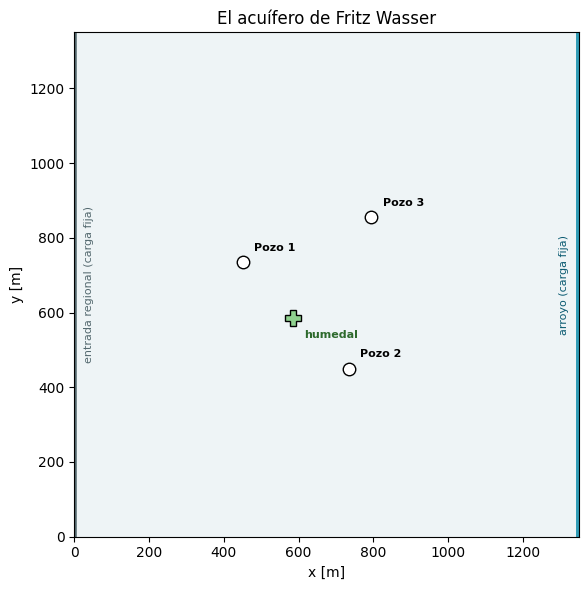

In [21]:
hidra.mapa()
plt.show()

El agua entra por la izquierda (frontera de carga fija), cruza el dominio y sale por el **arroyo** de la derecha. Los pozos están en
el centro y el humedal entre los pozos 1 y 2.

Una corrida del simulador es una sola línea. Devuelve un objeto `Resultado` con todo lo que necesitamos.

Resultado(bombeos=[300.0, 300.0, 300.0] m³/d → abatimientos en pozos=[2.69, 2.75, 2.76] m, humedal=1.43 m)
abatimiento en los pozos [m]: [2.69 2.75 2.76]
abatimiento en el humedal [m]: 1.43


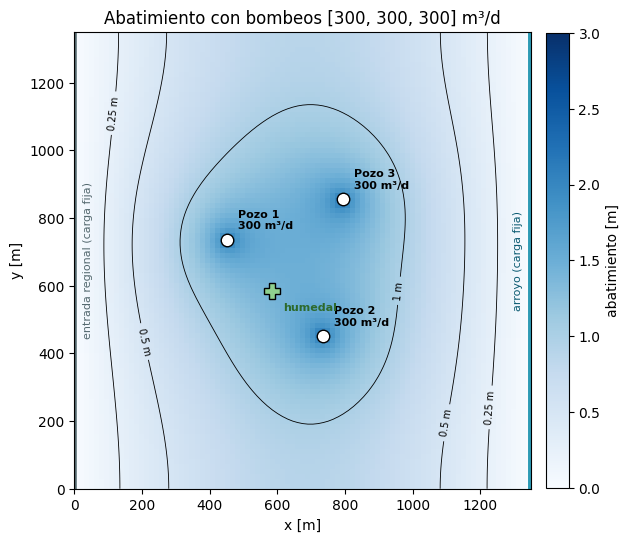

In [22]:
r = hidra.simular([300, 300, 300])     # p1, p2, p3 en m³/d
print(r)
print("abatimiento en los pozos [m]:", np.round(r.abatimiento_pozos, 2))
print("abatimiento en el humedal [m]:", round(r.abatimiento_humedal, 2))
hidra.mapa(r)
plt.show()

### 2.1 Qué es `hidra` y qué se le puede pedir

`hidra` es un **módulo de Python** (un archivo, `hidra.py`) escrito para este curso. Por dentro usa **rrwpt**, el modelo de flujo del
Laboratorio HIDRA (Rodríguez-Pretelín y Nowak, 2018): una malla de 90 × 90 celdas de 15 m, elementos finitos, acuífero confinado,
flujo estacionario. Por fuera, para ti, son cuatro funciones y un objeto. No necesitas saber nada más del simulador para todo el curso.

| Qué | Para qué sirve | Devuelve |
|---|---|---|
| `hidra.simular([p1, p2, p3])` | Una corrida con esos bombeos en m³/d | un `Resultado` |
| `hidra.mapa()` / `hidra.mapa(r)` | Dibuja el acuífero, o el cono de abatimiento de un resultado `r` | una figura |
| `hidra.matriz_respuesta()` | La matriz 3 × 3 de coeficientes de respuesta en los pozos (hoy la fabricaremos a mano) | un arreglo 3 × 3 |
| `hidra.graficar_region_factible(A, b, nombres, ...)` | Dibuja restricciones lineales en el plano $(p_1, p_2)$ | una figura |

Y las constantes del problema, para no escribir números sueltos: `hidra.S_MAX` (3 m), `hidra.S_MAX_HUMEDAL` (1.25 m),
`hidra.P3_COMPROMETIDO` (300 m³/d), `hidra.P_MAX` (1 000 m³/d), `hidra.LADO` (1 350 m).

Lo que devuelve `simular` es un objeto `Resultado`. Se lee con un punto: `r.algo`.

| Atributo de `r` | Qué contiene |
|---|---|
| `r.bombeos` | Los tres bombeos que pediste |
| `r.abatimiento_pozos` | Arreglo de 3 abatimientos [m], uno por pozo |
| `r.abatimiento_humedal` | Abatimiento [m] en el humedal |
| `r.abatimiento_maximo` | El mayor abatimiento de todo el acuífero [m] |
| `r.campo` | **Matriz 91 × 91** con el abatimiento en cada nodo (fila = y, columna = x) |
| `r.en(x, y)` | Abatimiento [m] en el punto (x, y) en metros, el que tú quieras |

Tres ejemplos de uso:

In [23]:
r = hidra.simular([200, 500, 300])

# 1) ¿cuánto baja el nivel en un punto cualquiera? Por ejemplo, en el centro del dominio y junto al arroyo
print("en el centro (675, 675):", round(r.en(675, 675), 3), "m")
print("junto al arroyo (1300, 675):", round(r.en(1300, 675), 3), "m   (casi cero: la carga está fija ahí)")

# 2) el campo completo es una matriz: podemos preguntarle cosas con NumPy
print("campo:", r.campo.shape, "| abatimiento máximo del acuífero:", round(r.campo.max(), 3), "m")
print("¿cuántos nodos tienen más de 1 m de abatimiento?", (r.campo > 1.0).sum(), "de", r.campo.size)

# 3) dónde están los pozos y el humedal, en metros
print("pozos (x, y):", hidra.pozos_xy())
print("humedal (x, y):", hidra.humedal_xy())

en el centro (675, 675): 1.665 m
junto al arroyo (1300, 675): 0.132 m   (casi cero: la carga está fija ahí)
campo: (91, 91) | abatimiento máximo del acuífero: 4.063 m
¿cuántos nodos tienen más de 1 m de abatimiento? 2878 de 8281
pozos (x, y): [(450.0, 735.0), (735.0, 450.0), (795.0, 855.0)]
humedal (x, y): (585.0, 585.0)


Hay una opción más que usaremos en la Sesión 4: `hidra.simular(p, geologia=k)` con `k` de 0 a 9 corre el mismo problema sobre
una de diez geologías heterogéneas distintas. Hoy no la necesitamos; el acuífero de hoy es el homogéneo equivalente.

✏️ **Inténtalo:** pide `r.en(...)` en las coordenadas del pozo 1, `(450, 735)`, y compara con `r.abatimiento_pozos[0]`. Deben coincidir.

### 2.2 Los cinco conceptos, con hidra

En la teoría vimos cinco palabras: **variables de decisión, función objetivo, restricciones, región factible y óptimo global**.
Vamos a verlas sobre el acuífero de Fritz, con tres decisiones de ejemplo que llamaremos A, B y C.

**Variables de decisión.** Lo que elegimos son los bombeos. Cambiar la decisión cambia el acuífero entero:

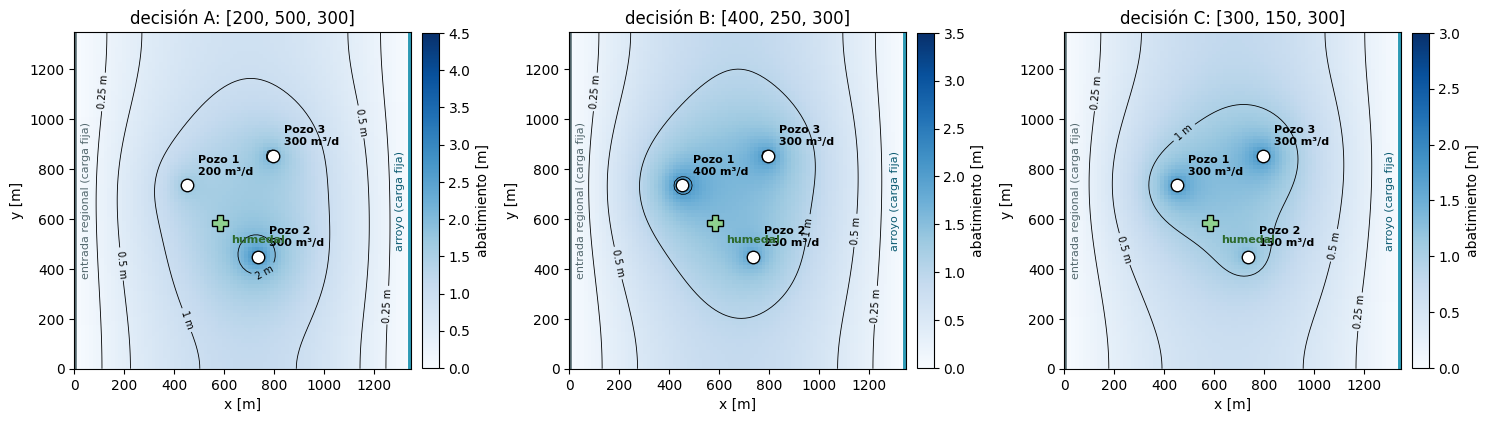

In [24]:
decisiones = {"A": [200, 500, 300], "B": [400, 250, 300], "C": [300, 150, 300]}

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
resultados = {}
for ax, (nombre, p) in zip(axs, decisiones.items()):
    r = hidra.simular(p)
    resultados[nombre] = r
    hidra.mapa(r, ax=ax, titulo=f"decisión {nombre}: {p}")
plt.tight_layout(); plt.savefig("Información/figuras/conceptos_variables.png", dpi=150); plt.show()

**Función objetivo.** Lo que queremos maximizar: el bombeo total $Z = p_1 + p_2 + p_3$. Y **restricciones**: las reglas que cada decisión respeta o rompe.

In [25]:
print(f"{'decisión':9s} {'Z [m³/d]':>9s}   {'s pozos [m]':>22s}   {'s humedal':>9s}   veredicto")
for nombre, p in decisiones.items():
    r = resultados[nombre]
    ok = (r.abatimiento_pozos <= hidra.S_MAX).all() and (r.abatimiento_humedal <= hidra.S_MAX_HUMEDAL)
    print(f"{nombre:9s} {sum(p):9.0f}   {str(np.round(r.abatimiento_pozos, 2)):>22s}   {r.abatimiento_humedal:9.2f}   {'FACTIBLE ✅' if ok else 'INFACTIBLE ❌'}")

decisión   Z [m³/d]              s pozos [m]   s humedal   veredicto
A              1000         [2.22 4.06 2.85]        1.63   INFACTIBLE ❌
B               950         [3.32 2.5  2.82]        1.51   INFACTIBLE ❌
C               750         [2.53 1.69 2.6 ]        1.15   FACTIBLE ✅


A y B bombean más que C, pero rompen alguna regla (el pozo 2 en A, el pozo 1 y el humedal en B). C respeta todas... pero ¿es la mejor? Para responder hay que ver **todas** las
decisiones a la vez.

**Región factible.** Con el pozo 3 fijo, cada decisión es un punto del plano $(p_1, p_2)$. `hidra` ya sabe fabricar la matriz de
respuesta (en la sección 4 lo haremos nosotros a mano); con ella, cada restricción es una recta y la región factible es el polígono
que queda dentro de todas:

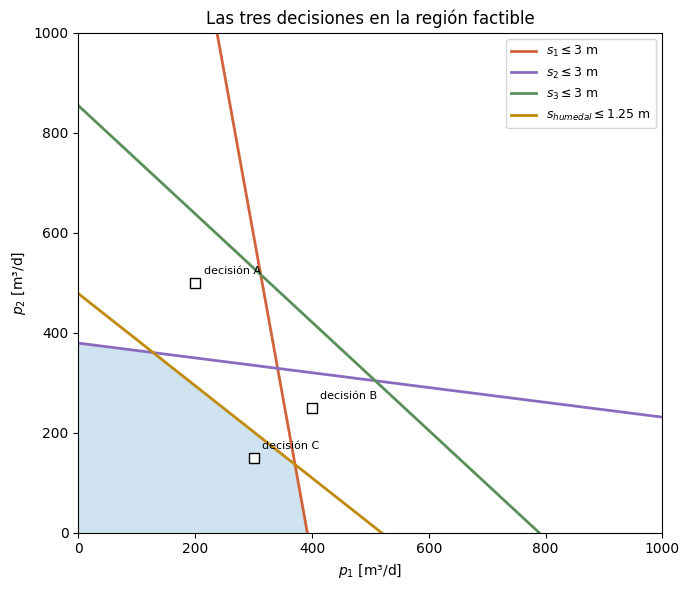

In [26]:
alpha = hidra.matriz_respuesta()              # en la sección 4 la fabricaremos nosotros
alpha_humedal = hidra.coeficientes_humedal()
p3 = hidra.P3_COMPROMETIDO
A_todas = np.vstack([alpha[:, :2], alpha_humedal[:2]])
b_todas = np.concatenate([hidra.S_MAX - alpha[:, 2] * p3, [hidra.S_MAX_HUMEDAL - alpha_humedal[2] * p3]])

hidra.graficar_region_factible(A_todas, b_todas, ["$s_1 \\leq 3$ m", "$s_2 \\leq 3$ m", "$s_3 \\leq 3$ m", "$s_{humedal} \\leq 1.25$ m"],
                               puntos=[((p[0], p[1]), f"decisión {n}") for n, p in decisiones.items()],
                               titulo="Las tres decisiones en la región factible")
plt.savefig("Información/figuras/conceptos_region.png", dpi=150); plt.show()

C cae dentro del polígono; A y B, fuera. **Óptimo global** es el punto del polígono con la mayor $p_1 + p_2$. Lo encontraremos
con certificado en la sección 5, y verás que está en una esquina: es la quinta palabra y la razón de ser de esta sesión.

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 3 · PRUEBA Y ERROR</p>

## 3 · Prueba y error (4 min)

Antes de usar ningún método, hagamos lo que haría cualquiera: **probar**. La siguiente función corre el simulador y dice si
una propuesta de bombeos respeta las reglas.

In [27]:
if "INTENTOS" not in globals():
    INTENTOS = []                                # tus intentos: sobreviven si vuelves a ejecutar esta celda

def evaluar(p1, p2, con_humedal=True):
    r = hidra.simular([p1, p2, hidra.P3_COMPROMETIDO])
    s = r.abatimiento_pozos
    tol = 1e-6                                   # tolerancia numérica: 3.0000000001 m cuenta como 3 m
    ok_pozos = (s <= hidra.S_MAX + tol).all()
    ok_humedal = (r.abatimiento_humedal <= hidra.S_MAX_HUMEDAL + tol) or (not con_humedal)
    veredicto = "FACTIBLE ✅" if (ok_pozos and ok_humedal) else "INFACTIBLE ❌"
    if con_humedal:
        INTENTOS.append((p1, p2, bool(ok_pozos and ok_humedal)))
    print(f"p = ({p1:.2f}, {p2:.2f}, {hidra.P3_COMPROMETIDO:.0f}) → total {p1 + p2 + hidra.P3_COMPROMETIDO:.2f} m³/d | "
          f"s pozos = {np.round(s, 2)} | s humedal = {r.abatimiento_humedal:.2f} | {veredicto}")

evaluar(300, 300)
evaluar(400, 400)
evaluar(300, 150)

p = (300.00, 300.00, 300) → total 900.00 m³/d | s pozos = [2.69 2.75 2.76] | s humedal = 1.43 | INFACTIBLE ❌
p = (400.00, 400.00, 300) → total 1100.00 m³/d | s pozos = [3.47 3.57 2.98] | s humedal = 1.78 | INFACTIBLE ❌
p = (300.00, 150.00, 300) → total 750.00 m³/d | s pozos = [2.53 1.69 2.6 ] | s humedal = 1.15 | FACTIBLE ✅


Fíjate: 300 y 300 ya rompe la regla del humedal aunque los pozos estén bien. Con 300 y 150 todo se cumple, pero el total es menor.

✏️ **Inténtalo (3 minutos):** cambia los números y busca **el mayor total factible** que puedas. Anota tu mejor marca.

Luego piensa: ¿cuántas combinaciones de $(p_1, p_2)$ existen? Infinitas. ¿Cómo sabes que tu mejor marca es *la mejor*? No lo sabes.
Eso es exactamente lo que resuelve la optimización: **encontrar la mejor y demostrar que lo es**.

Cada vez que llamas a `evaluar`, tu intento queda guardado. Así se ven:

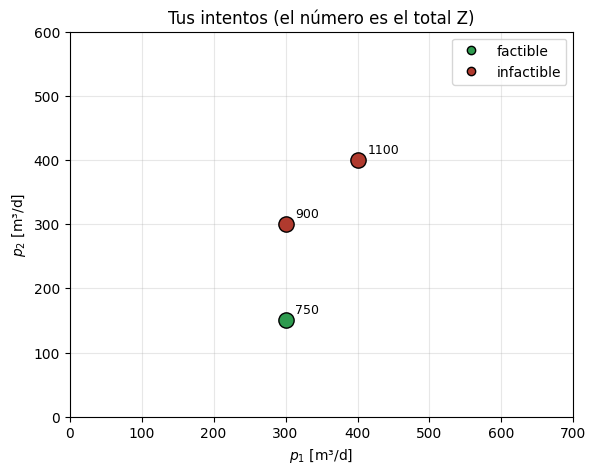

In [28]:
MIS_INTENTOS = list(INTENTOS)                    # una copia: la usaremos en la sección 6
fig, ax = plt.subplots(figsize=(6.5, 5))
for p1_, p2_, ok in MIS_INTENTOS:
    ax.plot(p1_, p2_, "o", ms=11, mfc="#2e9b4f" if ok else "#B03A2E", mec="k")
    ax.annotate(f"{p1_ + p2_ + hidra.P3_COMPROMETIDO:.0f}", (p1_, p2_), xytext=(7, 5), textcoords="offset points", fontsize=9)
ax.plot([], [], "o", mfc="#2e9b4f", mec="k", label="factible"); ax.plot([], [], "o", mfc="#B03A2E", mec="k", label="infactible")
ax.set_xlim(0, 700); ax.set_ylim(0, 600); ax.set_xlabel("$p_1$ [m³/d]"); ax.set_ylabel("$p_2$ [m³/d]")
ax.set_title("Tus intentos (el número es el total Z)"); ax.legend(); ax.grid(alpha=0.3); plt.show()

Los verdes y los rojos están separados por una **frontera** que todavía no vemos. En la sección 6 la dibujaremos encima de tus intentos.

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 4 · LA MATRIZ DE RESPUESTA</p>

## 4 · El simulador cabe en 12 números: la matriz de respuesta (8 min)

El acuífero de Fritz es confinado y el flujo es estacionario. Eso tiene una consecuencia matemática enorme: la ecuación de flujo
es **lineal**, y por tanto vale el **principio de superposición**: el abatimiento que producen tres pozos juntos es la **suma** de
los que produce cada uno por separado, y el de un pozo es **proporcional** a su bombeo.

Entonces basta con tres corridas, una por pozo con bombeo unitario de 1 m³/d, para saber cuánto abate cada pozo en cada punto.
A esos números se les llama **coeficientes de respuesta** $\alpha_{ij}$: abatimiento en el punto $i$ por cada m³/d bombeado en el pozo $j$.

Vamos a **fabricar** la matriz con el simulador, usando un ciclo `for`:

In [29]:
alpha = np.zeros((3, 3))            # matriz vacía 3x3: filas = pozos observados, columnas = pozos que bombean
alpha_humedal = np.zeros(3)         # una fila más: el humedal

for j in range(3):
    unitario = [0, 0, 0]
    unitario[j] = 1                  # solo el pozo j bombea, 1 m³/d
    r = hidra.simular(unitario)
    alpha[:, j] = r.abatimiento_pozos
    alpha_humedal[j] = r.abatimiento_humedal

np.set_printoptions(precision=6, suppress=True)
print("alpha [m por m³/d]:\n", alpha)
print("fila del humedal:", alpha_humedal)

alpha [m por m³/d]:
 [[0.006775 0.001047 0.001147]
 [0.001047 0.007071 0.001059]
 [0.001147 0.001059 0.006983]]
fila del humedal: [0.001692 0.001836 0.001239]


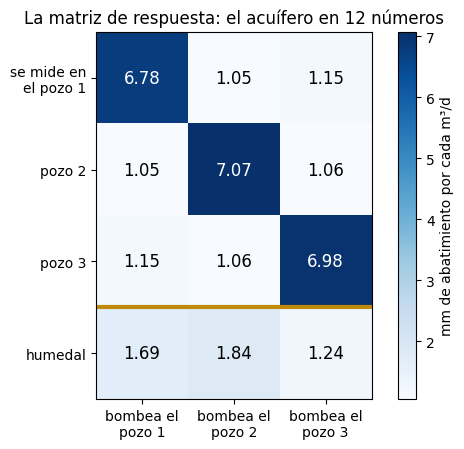

In [30]:
M = np.vstack([alpha, alpha_humedal]) * 1000     # en milímetros por m³/d, para leerla mejor
fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(M, cmap="Blues")
for i in range(4):
    for j in range(3):
        ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=12, color="white" if M[i, j] > 4 else "black")
ax.set_xticks(range(3), ["bombea el\npozo 1", "bombea el\npozo 2", "bombea el\npozo 3"])
ax.set_yticks(range(4), ["se mide en\nel pozo 1", "pozo 2", "pozo 3", "humedal"])
ax.axhline(2.5, color="#c08a0b", lw=3)
fig.colorbar(im, label="mm de abatimiento por cada m³/d")
ax.set_title("La matriz de respuesta: el acuífero en 12 números"); plt.tight_layout(); plt.show()

Lee la matriz: la diagonal (cada pozo sobre sí mismo) es grande, unos 0.007 m por m³/d; fuera de la diagonal (cada pozo sobre
los demás) es siete veces menor. Y es **simétrica**: el pozo 1 afecta al 2 igual que el 2 al 1.

Ahora la prueba de fuego. Si la superposición es cierta, para cualquier $p$ debe cumplirse $s = \alpha \, p$. Comparemos el
simulador completo contra la multiplicación de matriz:

In [31]:
p = np.array([250, 400, 300])
s_simulador = hidra.simular(p).abatimiento_pozos
s_matriz = alpha @ p

print("simulador:", np.round(s_simulador, 4))
print("alpha @ p :", np.round(s_matriz, 4))
print("diferencia máxima:", np.abs(s_simulador - s_matriz).max())

simulador: [2.457  3.4083 2.8054]
alpha @ p : [2.457  3.4083 2.8054]
diferencia máxima: 1.1430856261540612e-12


La superposición no vale solo en los tres pozos: vale en **todo el acuífero**. Simulemos cada pozo solo, sumemos los tres mapas y comparemos
con la corrida de los tres juntos.

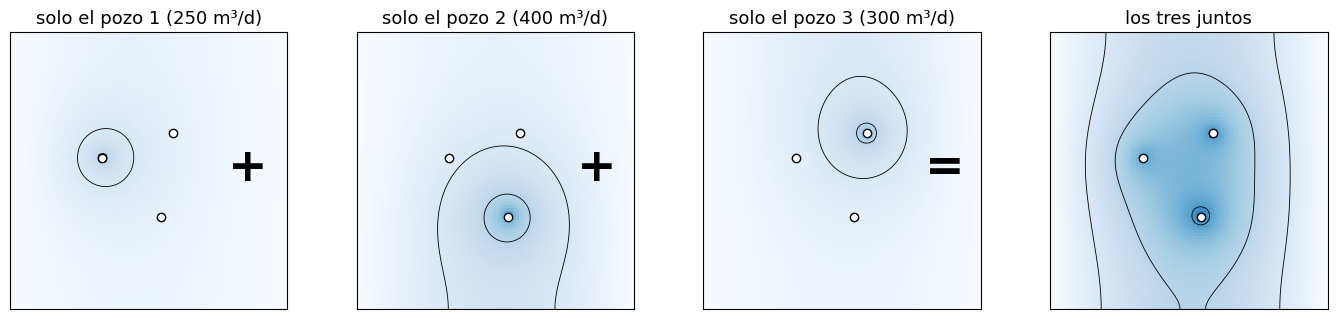

diferencia máxima entre la suma de los tres mapas y la corrida conjunta, en los 8 281 nodos: 2.1e-12 m


In [32]:
solos = [hidra.simular([p[0], 0, 0]), hidra.simular([0, p[1], 0]), hidra.simular([0, 0, p[2]])]
juntos = hidra.simular(p)
suma = solos[0].campo + solos[1].campo + solos[2].campo

fig, ejes = plt.subplots(1, 4, figsize=(17, 5.2))
tope = juntos.abatimiento_maximo
titulos = [f"solo el pozo 1 ({p[0]} m³/d)", f"solo el pozo 2 ({p[1]} m³/d)", f"solo el pozo 3 ({p[2]} m³/d)", "los tres juntos"]
for ax, campo, tit in zip(ejes, [r.campo for r in solos] + [juntos.campo], titulos):
    ax.imshow(campo, origin="lower", extent=[0, hidra.LADO, 0, hidra.LADO], cmap="Blues", vmin=0, vmax=tope)
    ax.contour(np.linspace(0, hidra.LADO, campo.shape[1]), np.linspace(0, hidra.LADO, campo.shape[0]), campo,
               levels=[0.5, 1, 2, 3], colors="k", linewidths=0.6)
    for x, y in hidra.pozos_xy():
        ax.plot(x, y, "o", ms=6, mfc="white", mec="k")
    ax.set_title(tit, fontsize=13); ax.set_xticks([]); ax.set_yticks([])
for k, signo in enumerate(["+", "+", "="]):
    fig.text(0.265 + k * 0.205, 0.5, signo, fontsize=34, ha="center", va="center", fontweight="bold")
plt.subplots_adjust(wspace=0.25); plt.show()
print(f"diferencia máxima entre la suma de los tres mapas y la corrida conjunta, en los 8 281 nodos: {np.abs(suma - juntos.campo).max():.1e} m")

La diferencia es del orden de $10^{-12}$: cero numérico. **El simulador de 8 281 nodos cabe en 12 números** (9 de los pozos y 3 del humedal).
Esto es lo que convierte un problema de simulación en un problema de **programación lineal**, que sí sabemos resolver con garantía.

✏️ **Inténtalo:** cambia `p` por otros tres valores. ¿Sigue dando cero la diferencia? ¿Y si pones un bombeo de 5 000 m³/d? (Físicamente
absurdo, pero el modelo es lineal: la diferencia seguirá siendo cero. Esa es la limitación del modelo confinado, y la aceptamos hoy a propósito.)

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 5 · SOLUCIÓN EXACTA</p>

## 5 · Solución exacta con programación lineal (8 min)

Con $p_3 = 300$ fijo, el problema queda en **dos variables**, $p_1$ y $p_2$. Cada restricción $s_i \le s_{\max}$ se escribe
$\alpha_{i1} p_1 + \alpha_{i2} p_2 \le s_{\max} - \alpha_{i3} \cdot 300$: una recta en el plano $(p_1, p_2)$.

SciPy trae un resolvedor de programación lineal, `linprog`, que pide el problema en **forma estándar**:

$$\min\; c^\top x \qquad \text{s.a.}\qquad A_{ub}\, x \le b_{ub}, \qquad x_{\min} \le x \le x_{\max}$$

Dos detalles de traducción. `linprog` **minimiza**, y nosotros queremos maximizar $p_1 + p_2$: por eso $c = [-1, -1]$ (minimizar
$-Z$ es maximizar $Z$). Y la demanda fija del pozo 3 se pasa al lado derecho. Primero resolvamos **sin el humedal**, como en el ejemplo clásico:

In [33]:
from scipy.optimize import linprog

p3 = hidra.P3_COMPROMETIDO
A_pozos = alpha[:, :2]                          # columnas de p1 y p2, filas = 3 pozos
b_pozos = hidra.S_MAX - alpha[:, 2] * p3        # lo que queda de los 3 m después de lo que ya abate el pozo 3

sol = linprog(c=[-1, -1], A_ub=A_pozos, b_ub=b_pozos, bounds=[(0, hidra.P_MAX), (0, hidra.P_MAX)], method="highs")
p1_opt, p2_opt = sol.x
Z_opt = p1_opt + p2_opt + p3
print(f"Óptimo sin humedal:  p1* = {p1_opt:.2f}   p2* = {p2_opt:.2f}   p3 = {p3:.0f}   →   Z* = {Z_opt:.2f} m³/d")

Óptimo sin humedal:  p1* = 341.15   p2* = 328.77   p3 = 300   →   Z* = 969.92 m³/d


Comprobemos con el simulador que ese punto respeta las reglas de los pozos (el humedal entra en la sección 6), y veamos la geometría: la región factible es un polígono
y el óptimo está en una **esquina** (un vértice). Siempre es así en programación lineal, y es la razón de que exista garantía.

p = (341.15, 328.77, 300) → total 969.92 m³/d | s pozos = [3.   3.   2.83] | s humedal = 1.55 | FACTIBLE ✅


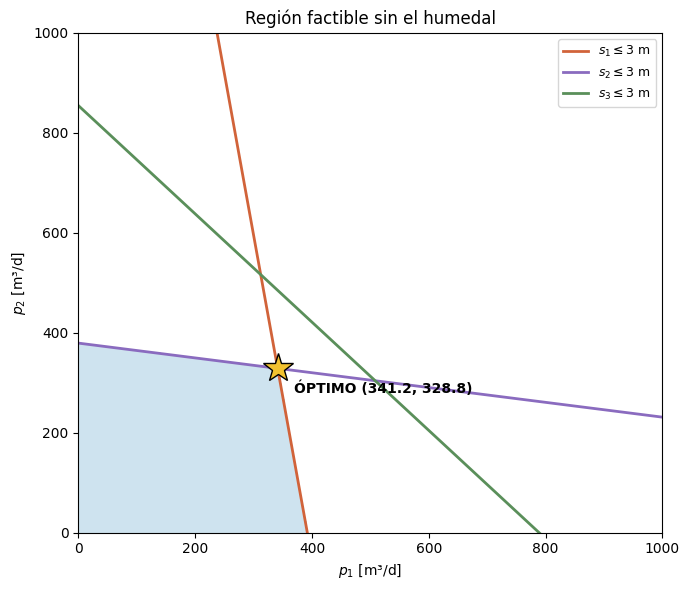

In [34]:
evaluar(p1_opt, p2_opt, con_humedal=False)   # de momento, sin la regla del humedal

hidra.graficar_region_factible(A_pozos, b_pozos, ["$s_1 \\leq 3$ m", "$s_2 \\leq 3$ m", "$s_3 \\leq 3$ m"],
                               p_optimo=(p1_opt, p2_opt), titulo="Región factible sin el humedal")
plt.savefig("Información/figuras/region_factible_pozos.png", dpi=150); plt.show()

Dos restricciones están **activas** (se cumplen con igualdad, $s_1 = s_2 = 3.00$ m) y la tercera tiene holgura. El óptimo es el vértice
donde se cruzan las dos rectas activas. Ese valor, **Z\* = 969.92 m³/d**, es la **verdad de referencia** del curso: el martes que viene un
enjambre de partículas intentará llegar a él sin usar la matriz.

Pero el humedal todavía no ha entrado. Mira el mapa del óptimo:

abatimiento en el humedal con ese óptimo: 1.55 m   (límite: 1.25 m)


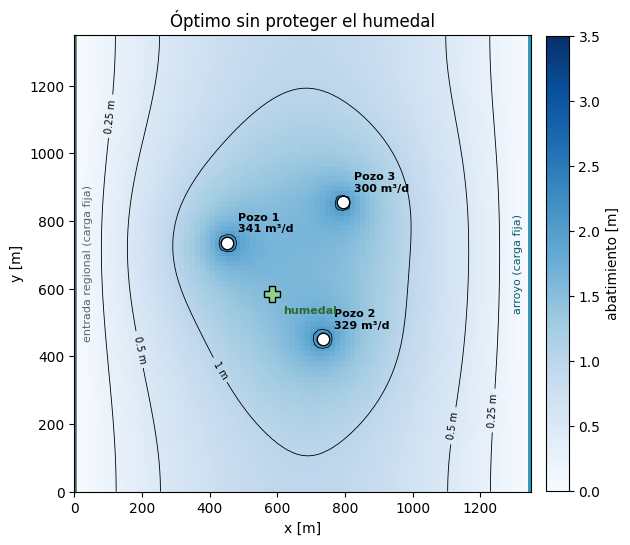

In [35]:
r_opt = hidra.simular([p1_opt, p2_opt, p3])
print("abatimiento en el humedal con ese óptimo:", round(r_opt.abatimiento_humedal, 2), "m   (límite:", hidra.S_MAX_HUMEDAL, "m)")
hidra.mapa(r_opt, titulo="Óptimo sin proteger el humedal")
plt.savefig("Información/figuras/mapa_optimo_pozos.png", dpi=150); plt.show()

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 6 · EL HUMEDAL</p>

## 6 · La matriz es el campo: entra el humedal (6 min)

El óptimo anterior abate el humedal más de lo permitido. Con una tabla de tres pozos esto sería invisible. Con el simulador no:
tenemos el abatimiento en **todos** los nodos, y cualquier punto del acuífero puede convertirse en **una fila más** de la matriz.
Ya fabricamos esa fila en la sección 4 (`alpha_humedal`). Solo hay que apilarla:

In [36]:
A_total = np.vstack([A_pozos, alpha_humedal[:2]])
b_total = np.concatenate([b_pozos, [hidra.S_MAX_HUMEDAL - alpha_humedal[2] * p3]])

sol_h = linprog(c=[-1, -1], A_ub=A_total, b_ub=b_total, bounds=[(0, hidra.P_MAX), (0, hidra.P_MAX)], method="highs")
p1_h, p2_h = sol_h.x
Z_h = p1_h + p2_h + p3
print(f"Óptimo con humedal:  p1* = {p1_h:.2f}   p2* = {p2_h:.2f}   p3 = {p3:.0f}   →   Z* = {Z_h:.2f} m³/d")
print(f"Proteger el humedal cuesta {Z_opt - Z_h:.1f} m³/d, y lo paga sobre todo el pozo {2 if (p2_opt - p2_h) > (p1_opt - p1_h) else 1}.")

evaluar(p1_h, p2_h)

Óptimo con humedal:  p1* = 370.88   p2* = 136.46   p3 = 300   →   Z* = 807.34 m³/d
Proteger el humedal cuesta 162.6 m³/d, y lo paga sobre todo el pozo 2.
p = (370.88, 136.46, 300) → total 807.34 m³/d | s pozos = [3.   1.67 2.66] | s humedal = 1.25 | FACTIBLE ✅


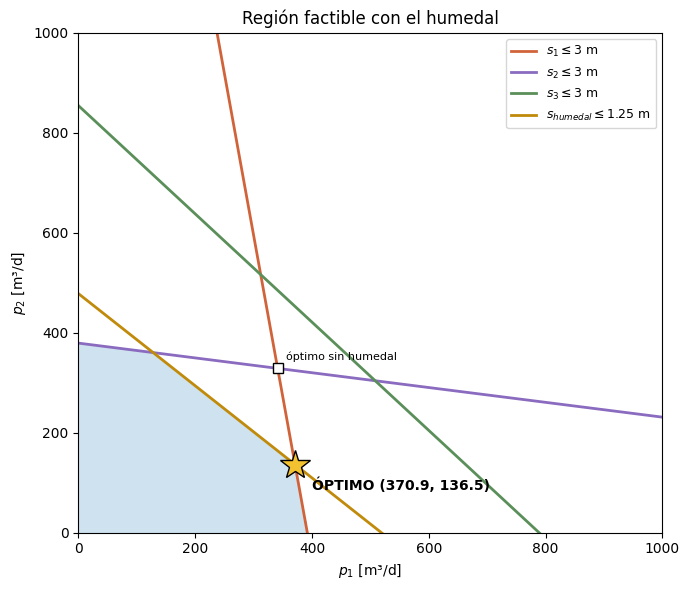

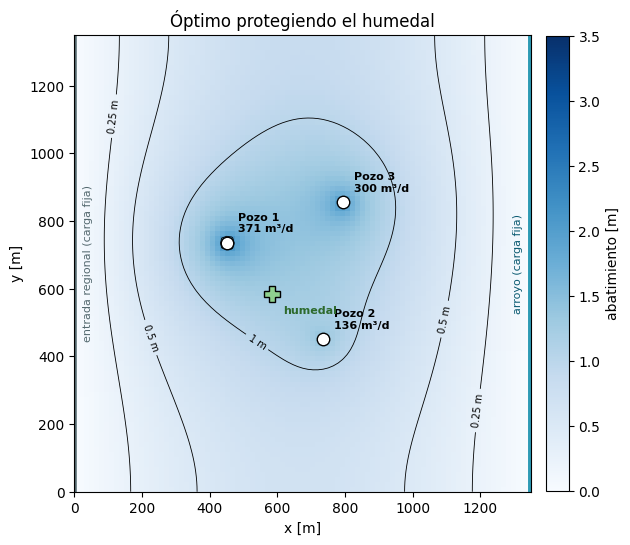

In [37]:
hidra.graficar_region_factible(A_total, b_total,
                               ["$s_1 \\leq 3$ m", "$s_2 \\leq 3$ m", "$s_3 \\leq 3$ m", "$s_{humedal} \\leq 1.25$ m"],
                               p_optimo=(p1_h, p2_h), puntos=[((p1_opt, p2_opt), "óptimo sin humedal")],
                               titulo="Región factible con el humedal")
plt.savefig("Información/figuras/region_factible_humedal.png", dpi=150); plt.show()

r_h = hidra.simular([p1_h, p2_h, p3])
hidra.mapa(r_h, titulo="Óptimo protegiendo el humedal")
plt.savefig("Información/figuras/mapa_optimo_humedal.png", dpi=150); plt.show()

Lee los dos mapas uno junto al otro. La curva de 1 m ya no toca el humedal, y la región factible perdió una esquina.
Ahora las restricciones activas son **el pozo 1 y el humedal**; el pozo 2 quedó con holgura. Esa es la lectura hidrogeológica
que Fritz necesita: *«puedes bombear 807 m³/d en total; si quieres más, el que estorba es el humedal, no tus bombas»*.

✏️ **Inténtalo:** cambia el límite del humedal, por ejemplo `hidra.S_MAX_HUMEDAL = 1.5` o `1.0`, vuelve a ejecutar desde la celda de
`A_total` y observa qué pasa con $Z^*$ y con el pozo 2. (Con 1.0 m el pozo 2 se apaga por completo.)

#### Tus intentos sobre la región factible

Ahora sí se ve la frontera: los intentos verdes cayeron dentro del polígono y los rojos fuera. Y el óptimo está en la esquina que nadie
encuentra a mano.

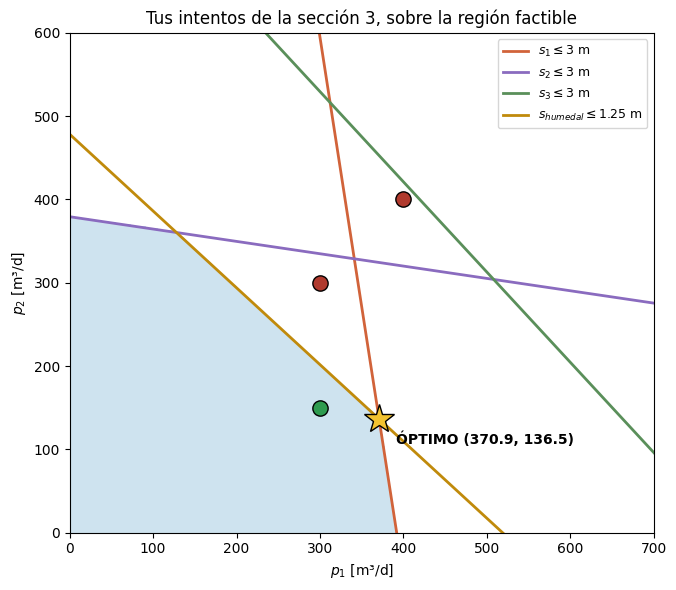

In [38]:
ax = hidra.graficar_region_factible(A_total, b_total,
                                    ["$s_1 \\leq 3$ m", "$s_2 \\leq 3$ m", "$s_3 \\leq 3$ m", "$s_{humedal} \\leq 1.25$ m"],
                                    p_optimo=(p1_h, p2_h), titulo="Tus intentos de la sección 3, sobre la región factible")
for p1_, p2_, ok in MIS_INTENTOS:
    ax.plot(p1_, p2_, "o", ms=11, mfc="#2e9b4f" if ok else "#B03A2E", mec="k", zorder=6)
ax.set_xlim(0, 700); ax.set_ylim(0, 600); plt.show()

#### El óptimo en corte: las dos reglas activas tocan su límite

La recta del pozo 1 al pozo 2 pasa justo por el humedal. Dibujemos el abatimiento a lo largo de ella, con y sin la regla del humedal.

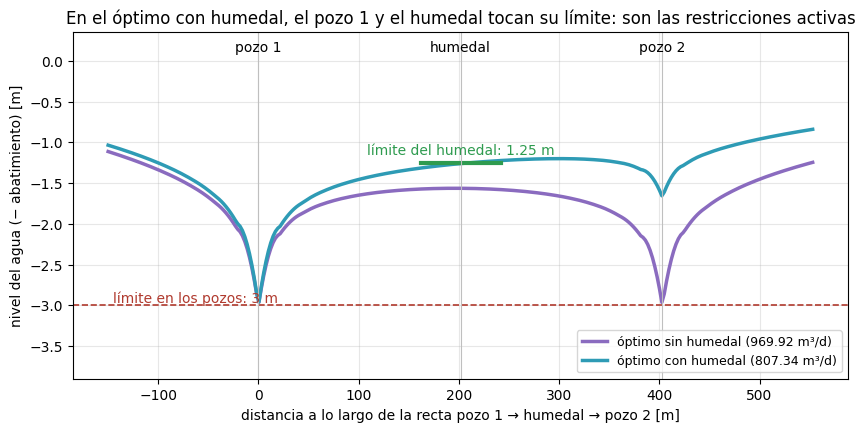

In [39]:
(x1, y1), (x2, y2) = hidra.pozos_xy()[0], hidra.pozos_xy()[1]
d = np.linspace(-150, np.hypot(x2 - x1, y2 - y1) + 150, 300)          # distancia desde el pozo 1, con un margen a cada lado
ux, uy = (x2 - x1) / np.hypot(x2 - x1, y2 - y1), (y2 - y1) / np.hypot(x2 - x1, y2 - y1)
d_hum = np.hypot(*(np.array(hidra.humedal_xy()) - np.array([x1, y1])))
fig, ax = plt.subplots(figsize=(10, 4.5))
from scipy.interpolate import RegularGridInterpolator
nodos = np.linspace(0, hidra.LADO, r_h.campo.shape[0])
for r, nombre, color in ((r_opt, "óptimo sin humedal (969.92 m³/d)", "#8a6bbf"), (r_h, "óptimo con humedal (807.34 m³/d)", "#2e9bb5")):
    campo = RegularGridInterpolator((nodos, nodos), r.campo)                  # interpola entre los nodos de la malla de 15 m
    ax.plot(d, -campo(np.column_stack([y1 + d * uy, x1 + d * ux])), lw=2.5, color=color, label=nombre)
ax.axhline(-3.0, color="#B03A2E", ls="--", lw=1.2); ax.text(d[0] + 5, -3.0, "límite en los pozos: 3 m", ha="left", va="bottom", color="#B03A2E")
ax.plot([d_hum - 40, d_hum + 40], [-1.25, -1.25], color="#2e9b4f", lw=3); ax.text(d_hum, -1.15, "límite del humedal: 1.25 m", ha="center", color="#2e9b4f")
for t, nombre in ((0, "pozo 1"), (d_hum, "humedal"), (np.hypot(x2 - x1, y2 - y1), "pozo 2")):
    ax.axvline(t, color="0.75", lw=0.8); ax.text(t, 0.12, nombre, ha="center", fontsize=10)
ax.set_ylim(-3.9, 0.35); ax.set_xlabel("distancia a lo largo de la recta pozo 1 → humedal → pozo 2 [m]")
ax.set_ylabel("nivel del agua (− abatimiento) [m]"); ax.legend(loc="lower right", fontsize=9); ax.grid(alpha=0.3)
ax.set_title("En el óptimo con humedal, el pozo 1 y el humedal tocan su límite: son las restricciones activas"); plt.show()

#### ¿Cuánto cuesta cada centímetro del humedal?

La pregunta que Fritz llevaría al regulador. Resolvemos el problema para muchos límites del humedal y graficamos el óptimo.

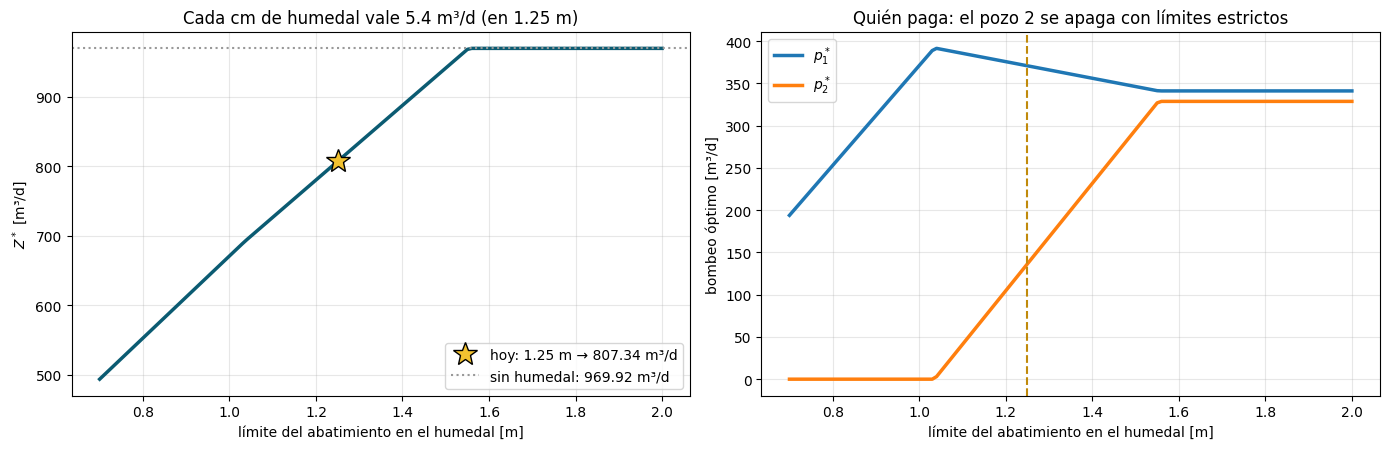

el humedal deja de estorbar desde 1.56 m; el pozo 2 se apaga por debajo de 1.04 m


In [40]:
limites = np.arange(0.70, 2.01, 0.01)
Z_lim, P_lim = [], []
for lim in limites:
    b_lim = np.concatenate([b_pozos, [lim - alpha_humedal[2] * p3]])
    r = linprog(c=[-1, -1], A_ub=A_total, b_ub=b_lim, bounds=[(0, hidra.P_MAX)] * 2, method="highs")
    Z_lim.append(r.x.sum() + p3 if r.status == 0 else np.nan); P_lim.append(r.x if r.status == 0 else [np.nan, np.nan])
Z_lim, P_lim = np.array(Z_lim), np.array(P_lim)
precio = -sol_h.ineqlin.marginals[-1] / 100      # m³/d que se ganan por cada cm más de humedal, en 1.25 m

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))
ax1.plot(limites, Z_lim, lw=2.5, color="#0B5B72")
ax1.plot(hidra.S_MAX_HUMEDAL, Z_h, "*", ms=18, mfc="#f2c230", mec="k", label=f"hoy: 1.25 m → {Z_h:.2f} m³/d")
ax1.axhline(Z_opt, color="0.6", ls=":", label=f"sin humedal: {Z_opt:.2f} m³/d")
ax1.set_xlabel("límite del abatimiento en el humedal [m]"); ax1.set_ylabel("$Z^*$ [m³/d]"); ax1.legend(); ax1.grid(alpha=0.3)
ax1.set_title(f"Cada cm de humedal vale {precio:.1f} m³/d (en 1.25 m)")
ax2.plot(limites, P_lim[:, 0], lw=2.5, label="$p_1^*$"); ax2.plot(limites, P_lim[:, 1], lw=2.5, label="$p_2^*$")
ax2.axvline(hidra.S_MAX_HUMEDAL, color="#c08a0b", ls="--")
ax2.set_xlabel("límite del abatimiento en el humedal [m]"); ax2.set_ylabel("bombeo óptimo [m³/d]"); ax2.legend(); ax2.grid(alpha=0.3)
ax2.set_title("Quién paga: el pozo 2 se apaga con límites estrictos")
plt.tight_layout(); plt.show()
print(f"el humedal deja de estorbar desde {limites[np.argmax(np.isclose(Z_lim, Z_opt, atol=0.01))]:.2f} m;"
      f" el pozo 2 se apaga por debajo de {limites[np.argmax(P_lim[:, 1] > 0.01)]:.2f} m")

A ese número, lo que se gana por relajar una restricción una unidad, se le llama **precio sombra**. `linprog` lo da gratis (`sol_h.ineqlin.marginals`):
es otra ventaja del método clásico que las metaheurísticas no tienen.

#### Tu mejor marca contra el óptimo

¿Te acuerdas de tu mejor marca de la sección 3, a prueba y error, con el humedal? Compárala con el óptimo con garantía.

In [41]:
MI_MEJOR_MARCA = 750      # ✏️ escribe el total (m³/d) de tu mejor marca de la sección 3
print(f"Tu mejor marca: {MI_MEJOR_MARCA:.0f} m³/d | el óptimo con garantía: {Z_h:.2f} m³/d | "
      f"te faltaban {Z_h - MI_MEJOR_MARCA:.1f} m³/d ({100 * (Z_h - MI_MEJOR_MARCA) / Z_h:.1f} %)")

Tu mejor marca: 750 m³/d | el óptimo con garantía: 807.34 m³/d | te faltaban 57.3 m³/d (7.1 %)


<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 7 · LO QUE PUEDE SALIR MAL</p>

## 7 · Lo que puede salir mal (7 min)

`linprog` no siempre encuentra un óptimo. Hay tres situaciones que hay que saber reconocer y **leer en términos hidrogeológicos**. Las provocamos a propósito
con el problema de Fritz. `linprog` lo avisa con `status` (0 = encontró el óptimo, 2 = infactible, 3 = no acotado) y un mensaje.

In [42]:
def resolver(A, b, cotas, nombre):
    # resuelve el problema de Fritz con las reglas (A, b) y las cotas de cada bomba, y reporta qué pasó
    r = linprog(c=[-1, -1], A_ub=A, b_ub=b, bounds=cotas, method="highs")
    texto = f"{nombre:42s} status {r.status}: {r.message.split('(')[0].strip()}"
    if r.status == 0:
        texto += f"  →  p1 = {r.x[0]:.2f}, p2 = {r.x[1]:.2f}, Z = {r.x.sum() + p3:.2f} m³/d"
    print(texto)
    return r

resolver(A_total, b_total, [(0, hidra.P_MAX)] * 2, "el problema de hoy")

el problema de hoy                         status 0: Optimization terminated successfully.  →  p1 = 370.88, p2 = 136.46, Z = 807.34 m³/d


        message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
        success: True
         status: 0
            fun: -507.34040295577324
              x: [ 3.709e+02  1.365e+02]
            nit: 3
          lower:  residual: [ 3.709e+02  1.365e+02]
                 marginals: [ 0.000e+00  0.000e+00]
          upper:  residual: [ 6.291e+02  8.635e+02]
                 marginals: [ 0.000e+00  0.000e+00]
          eqlin:  residual: []
                 marginals: []
        ineqlin:  residual: [ 0.000e+00  1.329e+00  3.351e-01  0.000e+00]
                 marginals: [-1.347e+01 -0.000e+00 -0.000e+00 -5.370e+02]
 mip_node_count: 0
 mip_dual_bound: 0.0
        mip_gap: 0.0

### 7.1 No acotado: el objetivo crece sin límite

Ocurre cuando **falta una restricción**. ¿Y si olvidamos la capacidad de las bombas (1 000 m³/d)? ¿Y si además olvidamos las reglas de abatimiento?

In [43]:
resolver(A_total, b_total, [(0, None)] * 2, "sin la capacidad de las bombas")
resolver(None, None, [(0, None)] * 2, "sin las reglas de abatimiento ni la capacidad")

sin la capacidad de las bombas             status 0: Optimization terminated successfully.  →  p1 = 370.88, p2 = 136.46, Z = 807.34 m³/d
sin las reglas de abatimiento ni la capacidad status 3: The problem is unbounded.


       message: The problem is unbounded. (HiGHS Status 10: model_status is Unbounded; primal_status is Feasible)
       success: False
        status: 3
           fun: None
             x: None
           nit: 0
         lower:  residual: None
                marginals: None
         upper:  residual: None
                marginals: None
         eqlin:  residual: None
                marginals: None
       ineqlin:  residual: None
                marginals: None

Sin la capacidad de las bombas **no pasa nada**: el acuífero mismo limita el bombeo (los 3 m y el humedal llegan antes que los 1 000 m³/d). Pero sin las
reglas de abatimiento no hay nada que detenga a $Z$: **no acotado**. En la práctica significa que el modelo olvidó algo físico.

### 7.2 Infactible: las reglas se contradicen

Ocurre cuando **ninguna decisión** cumple todas las reglas a la vez. Por ejemplo, si el contrato del pozo 3 sube a 500 m³/d:

In [44]:
p3_contrato = 500
b_contrato = np.concatenate([hidra.S_MAX - alpha[:, 2] * p3_contrato, [hidra.S_MAX_HUMEDAL - alpha_humedal[2] * p3_contrato]])
resolver(A_total, b_contrato, [(0, hidra.P_MAX)] * 2, "contrato del pozo 3 en 500 m³/d")
print(f"el pozo 3, solo y con 500 m³/d, abate su propio pozo {alpha[2, 2] * p3_contrato:.2f} m: ya rompe la regla de 3 m aunque p1 = p2 = 0")

contrato del pozo 3 en 500 m³/d            status 2: The problem is infeasible.
el pozo 3, solo y con 500 m³/d, abate su propio pozo 3.49 m: ya rompe la regla de 3 m aunque p1 = p2 = 0


Aunque los pozos 1 y 2 se apaguen, el pozo 3 ya rompe su propia regla: **no existe región factible**. La lectura para Fritz: *«ese contrato no se puede
cumplir sin violar la norma; hay que renegociarlo»*.

### 7.3 Degenerado: una variable vale cero

No es un error: el óptimo existe, pero queda en un **eje**. Si la autoridad baja el límite del humedal a 1.0 m:

In [45]:
b_estricto = b_total.copy()
b_estricto[-1] = 1.0 - alpha_humedal[2] * p3          # la regla del humedal, ahora con 1.0 m
resolver(A_total, b_estricto, [(0, hidra.P_MAX)] * 2, "humedal a 1.0 m")

humedal a 1.0 m                            status 0: Optimization terminated successfully.  →  p1 = 371.19, p2 = 0.00, Z = 671.19 m³/d


        message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
        success: True
         status: 0
            fun: -371.19151399646347
              x: [ 3.712e+02  0.000e+00]
            nit: 1
          lower:  residual: [ 3.712e+02  0.000e+00]
                 marginals: [ 0.000e+00  8.488e-02]
          upper:  residual: [ 6.288e+02  1.000e+03]
                 marginals: [ 0.000e+00  0.000e+00]
          eqlin:  residual: []
                 marginals: []
        ineqlin:  residual: [ 1.408e-01  2.293e+00  4.793e-01  0.000e+00]
                 marginals: [-0.000e+00 -0.000e+00 -0.000e+00 -5.909e+02]
 mip_node_count: 0
 mip_dual_bound: 0.0
        mip_gap: 0.0

El óptimo **apaga el pozo 2**: es el que más abate al humedal por cada m³/d. Matemáticamente es un vértice sobre el eje $p_2 = 0$; hidrogeológicamente,
*«con esa norma, el pozo 2 no conviene»*.

#### Los tres casos, dibujados

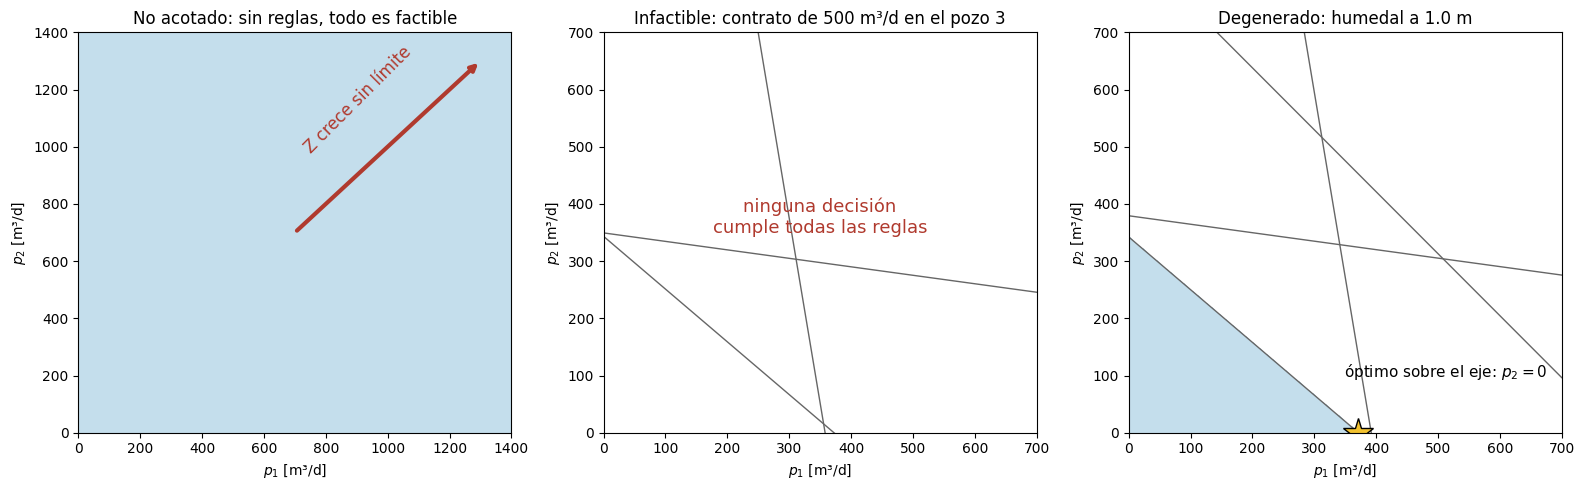

In [46]:
def region(ax, A, b, titulo, xmax=1400):
    g = np.linspace(0, xmax, 400); G1, G2 = np.meshgrid(g, g)
    ok = np.ones_like(G1, bool)
    if A is not None:
        for (a1, a2), bk in zip(A, b):
            ok &= a1 * G1 + a2 * G2 <= bk
            ax.plot(g, (bk - a1 * g) / a2, color="0.4", lw=1)
    if ok.any():
        ax.contourf(G1, G2, ok, levels=[0.5, 1.5], colors=["#9ec9e0"], alpha=0.6)
    ax.set_xlim(0, xmax); ax.set_ylim(0, xmax); ax.set_xlabel("$p_1$ [m³/d]"); ax.set_ylabel("$p_2$ [m³/d]"); ax.set_title(titulo)

fig, ejes = plt.subplots(1, 3, figsize=(16, 5))
region(ejes[0], None, None, "No acotado: sin reglas, todo es factible")
ejes[0].annotate("", xy=(1300, 1300), xytext=(700, 700), arrowprops=dict(arrowstyle="-|>", lw=3, color="#B03A2E"))
ejes[0].text(720, 980, "Z crece sin límite", color="#B03A2E", fontsize=12, rotation=45)
region(ejes[1], A_total, b_contrato, "Infactible: contrato de 500 m³/d en el pozo 3", xmax=700)
ejes[1].text(350, 350, "ninguna decisión\ncumple todas las reglas", ha="center", fontsize=13, color="#B03A2E")
r_deg = linprog(c=[-1, -1], A_ub=A_total, b_ub=b_estricto, bounds=[(0, hidra.P_MAX)] * 2, method="highs")
region(ejes[2], A_total, b_estricto, "Degenerado: humedal a 1.0 m", xmax=700)
ejes[2].plot(*r_deg.x, "*", ms=22, mfc="#f2c230", mec="k"); ejes[2].annotate("óptimo sobre el eje: $p_2 = 0$", r_deg.x, xytext=(-10, 40),
                                                                             textcoords="offset points", fontsize=11)
plt.tight_layout(); plt.show()

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 8 · ¿CUÁNDO BASTA EL MÉTODO CLÁSICO?</p>

## 8 · ¿Cuándo basta el método clásico? (8 min)

### 8.1 El problema de Fritz en los cuatro ejes

| Eje | El problema de hoy | Si cambiara a… | …ya no bastaría `linprog` porque |
|---|---|---|---|
| Objetivo y restricciones | **lineales** (superposición) | el costo de la energía, que crece con el abatimiento | el objetivo deja de ser $c^\top x$ |
| Variables | **continuas** (m³/d) | decidir qué pozos perforar u operar | las variables son sí o no |
| Número de objetivos | **uno** (el agua) | agua, costo y humedal a la vez | no hay un solo óptimo, sino un frente (sesión 3) |
| Conocimiento | **determinista** (una geología) | muchas geologías posibles | hay que decidir con incertidumbre (sesión 4) |

Hoy el problema cayó en las cuatro columnas fáciles: por eso `linprog` bastó, en milisegundos y **con garantía**.

### 8.2 Fritz paga la luz: un objetivo no lineal

Fritz vende el agua de los pozos 1 y 2 a $P = 0.11$ \$/m³, pero paga la energía de subirla. La altura de bombeo es la profundidad al nivel estático más el
abatimiento, así que el costo **crece con el abatimiento**:

$$
\max\; B(p_1, p_2) = \sum_{i=1}^{2} \Big[ P\,p_i \;-\; c_i\,p_i\,\big(\text{H}_i - h_i^0 + s_i(\mathbf{p})\big) \Big]
$$

con $c = 0.01, 0.015$ \$ por m³ y metro, cota del terreno $\text{H} = 40$ m, nivel estático $h^0 = 34$ m, y las mismas reglas de hoy. Como $s_i$ depende de
los bombeos, $B$ tiene términos $p_i\,p_j$: **no es lineal**, y `linprog` (que solo acepta $c^\top x$) no lo puede resolver.

In [47]:
PRECIO = 0.11                                     # $ por m³
C_E = np.array([0.01, 0.015])                     # costo de la energía de los pozos 1 y 2 [$ por m³ y por metro de altura]
ALTURA = 40.0 - 34.0                              # cota del terreno menos nivel estático [m]

def beneficio(p1, p2):
    s = alpha @ np.array([p1, p2, p3])            # el abatimiento en los pozos, con la matriz
    return float(np.sum(PRECIO * np.array([p1, p2]) - C_E * np.array([p1, p2]) * (ALTURA + s[:2])))

def factible(p1, p2):
    x = np.array([p1, p2, p3])
    return bool((alpha @ x <= hidra.S_MAX + 1e-9).all() and alpha_humedal @ x <= hidra.S_MAX_HUMEDAL + 1e-9)

for p in [(370.88, 136.46), (300, 50), (100, 100)]:
    print(f"p = {p}: beneficio {beneficio(*p):6.2f} $/d, factible: {factible(*p)}")

p = (370.88, 136.46): beneficio   6.73 $/d, factible: True
p = (300, 50): beneficio   7.97 $/d, factible: True
p = (100, 100): beneficio   4.18 $/d, factible: True


El óptimo de bombeo de la sección 6 (370.88, 136.46) **no** es el de mayor beneficio: bombear de más sale caro.

### 8.3 La idea de una metaheurística: proponer y calificar

Sin `linprog`, ¿cómo encontrar el máximo? La idea más simple de todas: **proponer decisiones al azar, calificar cada una y quedarse con la mejor**. No necesita
matriz, ni linealidad, ni fórmula: solo poder **calificar** una decisión. Es la búsqueda al azar, la abuela de las metaheurísticas.

In [48]:
def busqueda_al_azar(calificacion, n, semilla=0):
    rng = np.random.default_rng(semilla)
    mejor_valor, mejor_p, probadas = -np.inf, None, []
    for _ in range(n):
        p = rng.uniform(0, hidra.P_MAX, 2)                 # 1.- proponer una decisión al azar
        probadas.append(p)
        if not factible(*p):                               # 2.- ¿respeta las reglas? si no, se descarta
            continue
        valor = calificacion(*p)                           # 3.- calificarla
        if valor > mejor_valor:                            # 4.- quedarse con la mejor
            mejor_valor, mejor_p = valor, p
    return mejor_p, mejor_valor, np.array(probadas)

print("Primero, el problema de hoy (lineal), donde conocemos la verdad: Z* =", round(Z_h, 2), "m³/d")
for n in (100, 1_000, 10_000):
    p, z, _ = busqueda_al_azar(lambda p1, p2: p1 + p2 + p3, n)
    print(f"  {n:6d} decisiones al azar → mejor Z = {z:.2f} m³/d (le faltan {Z_h - z:.2f})")

Primero, el problema de hoy (lineal), donde conocemos la verdad: Z* = 807.34 m³/d
     100 decisiones al azar → mejor Z = 798.66 m³/d (le faltan 8.68)
    1000 decisiones al azar → mejor Z = 798.66 m³/d (le faltan 8.68)


   10000 decisiones al azar → mejor Z = 801.70 m³/d (le faltan 5.64)


Se acerca a 807.34, pero **nunca sabe** si ya llegó: no hay certificado. Ahora el problema que `linprog` no puede resolver:

búsqueda al azar (10 000 decisiones): p1 = 336.4, p2 = 33.5 m³/d → beneficio 8.09 $/d


malla fina:                            p1 = 338.0, p2 = 30.0 m³/d → beneficio 8.09 $/d


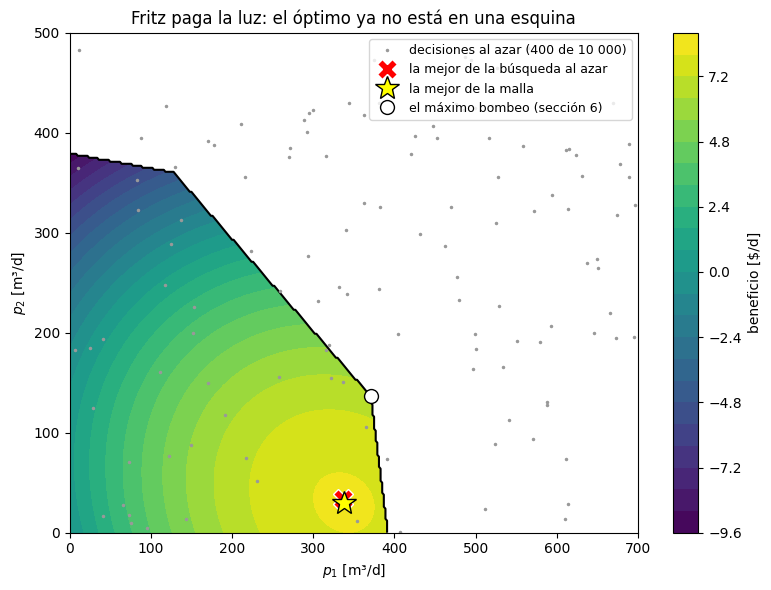

In [49]:
p_azar, B_azar, probadas = busqueda_al_azar(beneficio, 10_000)
print(f"búsqueda al azar (10 000 decisiones): p1 = {p_azar[0]:.1f}, p2 = {p_azar[1]:.1f} m³/d → beneficio {B_azar:.2f} $/d")

# para comprobarlo, una malla fina (cada 2 m³/d): posible aquí porque son solo dos variables
g = np.arange(0, hidra.P_MAX + 1, 2.0)
G1, G2 = np.meshgrid(g, g)
X = np.stack([G1.ravel(), G2.ravel(), np.full(G1.size, p3)], axis=1)
S = X @ alpha.T
legal = (S <= hidra.S_MAX + 1e-9).all(axis=1) & (X @ alpha_humedal <= hidra.S_MAX_HUMEDAL + 1e-9)
B_malla = (PRECIO * X[:, :2] - C_E * X[:, :2] * (ALTURA + S[:, :2])).sum(axis=1)
k = np.flatnonzero(legal)[np.argmax(B_malla[legal])]
print(f"malla fina:                            p1 = {X[k, 0]:.1f}, p2 = {X[k, 1]:.1f} m³/d → beneficio {B_malla[k]:.2f} $/d")

fig, ax = plt.subplots(figsize=(8, 6))
B_plano = np.where(legal, B_malla, np.nan).reshape(G1.shape)
cf = ax.contourf(G1, G2, B_plano, levels=25, cmap="viridis"); fig.colorbar(cf, label="beneficio [$/d]")
ax.contour(G1, G2, legal.reshape(G1.shape).astype(float), levels=[0.5], colors="k", linewidths=1.5)
ax.plot(probadas[:400, 0], probadas[:400, 1], ".", color="0.6", ms=3, label="decisiones al azar (400 de 10 000)")
ax.plot(*p_azar, "rX", ms=14, mec="w", label="la mejor de la búsqueda al azar")
ax.plot(X[k, 0], X[k, 1], "*", ms=18, mfc="yellow", mec="k", label="la mejor de la malla")
ax.plot(p1_h, p2_h, "o", ms=10, mfc="white", mec="k", label="el máximo bombeo (sección 6)")
ax.set_xlim(0, 700); ax.set_ylim(0, 500)
ax.set_xlabel("$p_1$ [m³/d]"); ax.set_ylabel("$p_2$ [m³/d]"); ax.legend(fontsize=9, loc="upper right")
ax.set_title("Fritz paga la luz: el óptimo ya no está en una esquina")
plt.tight_layout(); plt.show()

#### Cómo avanza la búsqueda al azar

La mejor marca después de cada evaluación. Las mismas 10 000 decisiones, calificadas con los dos objetivos.

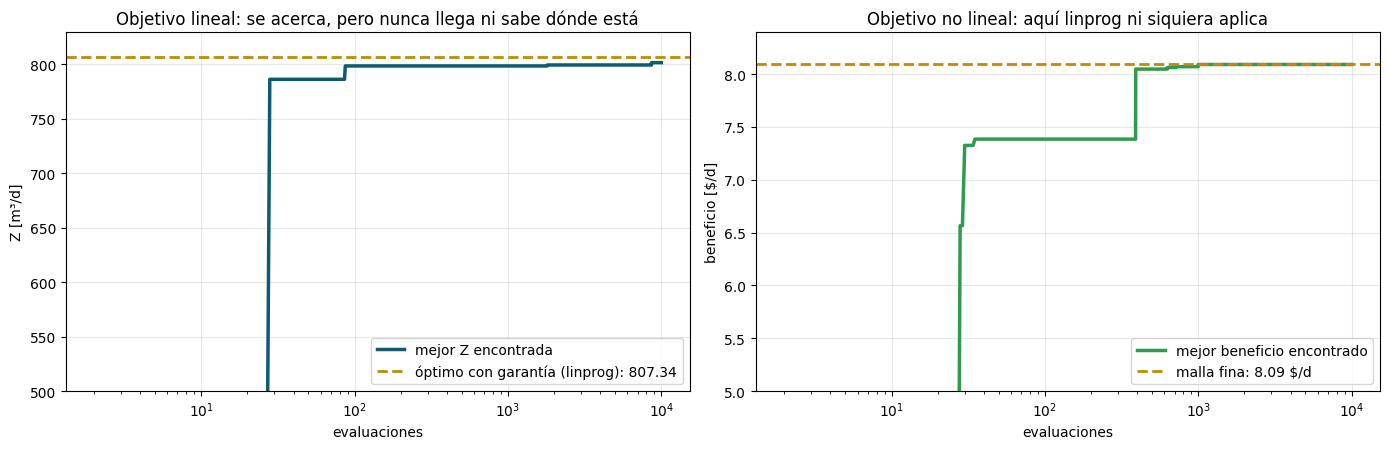

de las 10000 decisiones al azar, solo 10% cumplieron las reglas


In [50]:
ok_azar = np.array([factible(*q) for q in probadas])
Z_azar = np.where(ok_azar, probadas.sum(axis=1) + p3, -np.inf)
B_azar_todas = np.where(ok_azar, [beneficio(*q) for q in probadas], -np.inf)
n_eval = np.arange(1, len(probadas) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))
ax1.semilogx(n_eval, np.maximum.accumulate(Z_azar), lw=2.5, color="#0B5B72", label="mejor Z encontrada")
ax1.axhline(Z_h, color="#c08a0b", ls="--", lw=2, label=f"óptimo con garantía (linprog): {Z_h:.2f}")
ax1.set_ylim(500, 830); ax1.set_xlabel("evaluaciones"); ax1.set_ylabel("Z [m³/d]"); ax1.legend(loc="lower right"); ax1.grid(alpha=0.3)
ax1.set_title("Objetivo lineal: se acerca, pero nunca llega ni sabe dónde está")
ax2.semilogx(n_eval, np.maximum.accumulate(B_azar_todas), lw=2.5, color="#2e9b4f", label="mejor beneficio encontrado")
ax2.axhline(B_malla[k], color="#c08a0b", ls="--", lw=2, label=f"malla fina: {B_malla[k]:.2f} $/d")
ax2.set_ylim(5, 8.4); ax2.set_xlabel("evaluaciones"); ax2.set_ylabel("beneficio [$/d]"); ax2.legend(loc="lower right"); ax2.grid(alpha=0.3)
ax2.set_title("Objetivo no lineal: aquí linprog ni siquiera aplica")
plt.tight_layout(); plt.show()
print(f"de las {len(probadas)} decisiones al azar, solo {ok_azar.mean():.0%} cumplieron las reglas")

#### El beneficio en 3-D (gíralo con el mouse)

La superficie del beneficio sobre la región factible. Acerca, gira y pasa el mouse: el máximo es una **cima** dentro de la región, no una esquina.

In [51]:
import plotly.graph_objects as go
import plotly.io as pio
pio.renderers.default = "plotly_mimetype"         # el que dibuja VS Code (y JupyterLab)

sup = go.Surface(x=g, y=g, z=B_plano, colorscale="Viridis", colorbar=dict(title="$/d"),
                 hovertemplate="p1 = %{x:.0f}<br>p2 = %{y:.0f}<br>beneficio = %{z:.2f} $/d<extra></extra>")
cima = go.Scatter3d(x=[X[k, 0]], y=[X[k, 1]], z=[B_malla[k] + 0.15], mode="markers+text", text=["la cima"],
                    marker=dict(size=7, color="#f2c230", line=dict(color="black", width=1)))
fig3d = go.Figure([sup, cima])
fig3d.update_layout(title="Fritz paga la luz: la superficie del beneficio", height=560,
                    scene=dict(xaxis_title="p1 [m³/d]", yaxis_title="p2 [m³/d]", zaxis_title="beneficio [$/d]",
                               xaxis_range=[0, 700], yaxis_range=[0, 500]))
fig3d.show()

Tres lecciones, que son el puente al martes:

1. **El óptimo dejó la esquina.** Con un objetivo no lineal puede quedar **dentro** de la región: el pozo 1 a unos 2.7 m y ninguna regla en su límite. La garantía
   de los vértices se pierde.
2. **La búsqueda al azar lo encontró** sin matriz, sin fórmula y sin `linprog`: solo proponiendo y calificando. Si en lugar de la matriz calificara con
   `hidra.simular`, funcionaría igual con un acuífero libre, transitorio o con transporte.
3. **Pero es ciega y cara:** gastó 10 000 evaluaciones, nueve de cada diez cayeron fuera de las reglas, y nunca sabe si ya llegó. El martes, el **enjambre de
   partículas** hace lo mismo con inteligencia: cada partícula aprende de su mejor hallazgo y del mejor del grupo.

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 9 · CIERRE</p>

## 9 · Cierre: por qué funcionó, y qué viene (2 min)

Todo lo de hoy colgó de una sola palabra: **lineal**.

- La ecuación de flujo era lineal → valía la superposición → el simulador cabía en 12 números.
- Las restricciones eran lineales → la región factible era un polígono → el óptimo estaba en un vértice → `linprog` lo encontró **con garantía**.
- El objetivo también era lineal (el bombeo total). Con el costo de la energía (sección 8) dejó de serlo, el óptimo salió de la esquina y `linprog`
  ya no sirvió: la búsqueda al azar sí, pero sin garantía.

Ahora pregúntate qué pasa si el acuífero es libre (el espesor saturado cambia con el bombeo), si el régimen es transitorio, si el
objetivo involucra transporte de contaminantes o la zona de captura, o si el simulador es una caja negra que solo devuelve números.
En todos esos casos la matriz deja de existir y `linprog` no tiene nada que resolver. **Para eso están las metaheurísticas**,
y empezamos el martes con el enjambre de partículas, que volverá a este mismo acuífero y se medirá contra los 969.92 m³/d de hoy.

### Trabajo asíncrono (1 h) y Tarea 1

1. **La Tarea 1 es el primero de los cuatro cuadernos de evaluación del curso.** Se aprueba con 6 de 10; con 2 de los 4 cuadernos de tarea aprobados, el examen del curso está aprobado. Abre `Tarea_1_estudiante.ipynb` (en esta misma carpeta), escribe tu correo de inscripción
   y sigue sus cinco etapas: es el problema de hoy con **tus** datos (tu límite de humedal y tu contrato del pozo 3). Cada etapa trae su comprobación
   inmediata (`grader.check`). Unos 60 minutos. Guárdala como `Tarea_1_<tu nombre>.ipynb` y súbela al formulario del curso **antes del martes 10 de noviembre**.
2. Si Python todavía te cuesta, repasa el tutorial de Python y NumPy del curso (`Información/complementos/1_python_numpy_tutorial_ESP.ipynb`), al menos las secciones
   de listas, NumPy y Matplotlib. No se califica, pero la Tarea 1 lo da por sabido.
3. **Antes del martes 10**, haz la subsección 1.7 de este cuaderno (la caja de herramientas, unos 25 minutos): trae todo el Python que usan las sesiones 2 a 4.
4. Si quieres practicar antes de la tarea: vuelve a resolver la sección 6 con el límite del humedal en 1.0 m y en 1.5 m, y mira qué restricciones quedan activas.

### Referencias

- Peralta, R. C. (2012). *Groundwater Optimization Handbook: Flow, Contaminant Transport, and Conjunctive Management*. CRC Press. (El ejemplo clásico de los tres pozos.)
- Rodríguez-Pretelín, A. y Nowak, W. (2018). Integrating transient behavior as a new dimension to WHPA delineation. *Advances in Water Resources*, 119, 178–187. (El simulador rrwpt.)
- Ahlfeld, D. P. y Mulligan, A. E. (2000). *Optimal Management of Flow in Groundwater Systems*. Academic Press. (Matrices de respuesta y programación lineal en aguas subterráneas.)